In [76]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

sns.set_theme(style="whitegrid")

# Reproducibility
RANDOM_STATE = 42

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
# Dataset path
file_path = "bank-additional-full.csv"

# Load dataset
df = pd.read_csv(file_path, sep=";")

# Display the first five records
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nDataset shape:")
print(df.shape)

Number of rows: 41188
Number of columns: 21

Dataset shape:
(41188, 21)


In [6]:
print("Dataset columns:")

for column in df.columns:
    print(column)

Dataset columns:
age
job
marital
education
default
housing
loan
contact
month
day_of_week
duration
campaign
pdays
previous
poutcome
emp.var.rate
cons.price.idx
cons.conf.idx
euribor3m
nr.employed
y


In [7]:
assert len(df.columns) == 21
assert 'y' in df.columns
assert 'duration' in df.columns

print("Dataset structure verified.")

Dataset structure verified.


In [8]:
print("First five records:")
display(df.head())

print("Last five records:")
display(df.tail())

First five records:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Last five records:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,334,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,383,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,189,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,442,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,239,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [10]:
print("Numerical descriptive statistics:")

display(df.describe())

print("All columns descriptive statistics:")

display(df.describe(include="all"))

Numerical descriptive statistics:


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


All columns descriptive statistics:


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
count,41188.00000,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188.000000,41188.000000,41188.000000,41188.000000,41188,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188
unique,NaN,12,4,8,3,3,3,2,10,5,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN,2
top,NaN,admin.,married,university.degree,no,yes,no,cellular,may,thu,NaN,NaN,NaN,NaN,nonexistent,NaN,NaN,NaN,NaN,NaN,no
freq,NaN,10422,24928,12168,32588,21576,33950,26144,13769,8623,NaN,NaN,NaN,NaN,35563,NaN,NaN,NaN,NaN,NaN,36548
mean,40.02406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,258.285010,2.567593,962.475454,0.172963,NaN,0.081886,93.575664,-40.502600,3.621291,5167.035911,NaN
std,10.42125,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,259.279249,2.770014,186.910907,0.494901,NaN,1.570960,0.578840,4.628198,1.734447,72.251528,NaN
min,17.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,0.000000,0.000000,NaN,-3.400000,92.201000,-50.800000,0.634000,4963.600000,NaN
25%,32.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,102.000000,1.000000,999.000000,0.000000,NaN,-1.800000,93.075000,-42.700000,1.344000,5099.100000,NaN
50%,38.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,180.000000,2.000000,999.000000,0.000000,NaN,1.100000,93.749000,-41.800000,4.857000,5191.000000,NaN
75%,47.00000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,319.000000,3.000000,999.000000,0.000000,NaN,1.400000,93.994000,-36.400000,4.961000,5228.100000,NaN


In [11]:
display(
    pd.DataFrame({
        'Feature': df.columns,
        'Data Type': df.dtypes.astype(str).values,
        'Unique Values': df.nunique().values
    })
)

,Feature,Data Type,Unique Values
0,age,int64,78
1,job,object,12
2,marital,object,4
3,education,object,8
4,default,object,3
5,housing,object,3
6,loan,object,3
7,contact,object,2
8,month,object,10
9,day_of_week,object,5


In [12]:
# Customer counts
target_counts = df['y'].value_counts()

# Customer percentages
target_percentages = df['y'].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage': target_percentages.round(2)
})

display(target_summary)

,Count,Percentage
y,,
no,36548,88.73
yes,4640,11.27


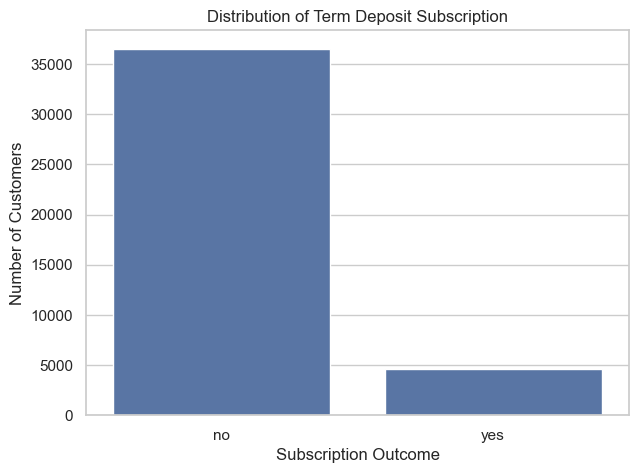

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='y',
    order=['no', 'yes']
)

plt.title('Distribution of Term Deposit Subscription')
plt.xlabel('Subscription Outcome')
plt.ylabel('Number of Customers')

plt.show()

In [14]:
categorical_columns = df.select_dtypes(
    include=['object']
).columns

for column in categorical_columns:

    print(f"\n{column}")
    print(df[column].value_counts(dropna=False))


job
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

marital
marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64

education
education
university.degree      12168
high.school             9515
basic.9y                6045
professional.course     5243
basic.4y                4176
basic.6y                2292
unknown                 1731
illiterate                18
Name: count, dtype: int64

default
default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

housing
housing
yes        21576
no         18622
unknown      990
Name: count, dtype: int64

loan
loan
no         33950
yes         6248
unknown      990
Name: count, dtype: int64

contact
contact
ce

In [15]:
unknown_counts = (
    df.select_dtypes(include=['object'])
      .eq('unknown')
      .sum()
      .sort_values(ascending=False)
)

display(
    unknown_counts[unknown_counts > 0]
)

default      8597
education    1731
housing       990
loan          990
job           330
marital        80
dtype: int64

In [16]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 12


In [17]:
missing_summary = pd.DataFrame({
    'Missing Count': df.isna().sum(),
    'Missing Percentage': (
        df.isna().mean() * 100
    ).round(2)
})

display(missing_summary)

,Missing Count,Missing Percentage
age,0,0.0
job,0,0.0
marital,0,0.0
education,0,0.0
default,0,0.0
housing,0,0.0
loan,0,0.0
contact,0,0.0
month,0,0.0
day_of_week,0,0.0


In [18]:
# Convert target to binary representation
target_mapping = {
    'no': 0,
    'yes': 1
}

y = df['y'].map(target_mapping)

print("Target encoding:")
print(y.value_counts().sort_index())

assert y.notna().all()

print("\nTarget encoding completed successfully.")

Target encoding:
y
0    36548
1     4640
Name: count, dtype: int64

Target encoding completed successfully.


In [19]:
# 3.1 Dataset Overview

# Dataset dimensions
print("Number of observations:", df.shape[0])
print("Number of attributes:", df.shape[1])

# Identify numerical and categorical columns
numerical_columns = df.select_dtypes(include=["number"]).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Remove the target from the categorical predictors
categorical_features = [
    col for col in categorical_columns if col != "y"
]

print("\nNumerical features:", len(numerical_columns))
print(numerical_columns)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

# Display data types
print("\nData types:")
display(df.dtypes)

# Summary statistics
display(df.describe())

Number of observations: 41188
Number of attributes: 21

Numerical features: 10
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical features: 10
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Data types:


age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [20]:
# 3.2 Target Variable Distribution

# Count each target category
target_counts = df["y"].value_counts()

# Calculate percentages
target_percentages = df["y"].value_counts(normalize=True) * 100

# Combine results into a table
target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

display(target_summary.round(2))

,Count,Percentage
y,,
no,36548,88.73
yes,4640,11.27


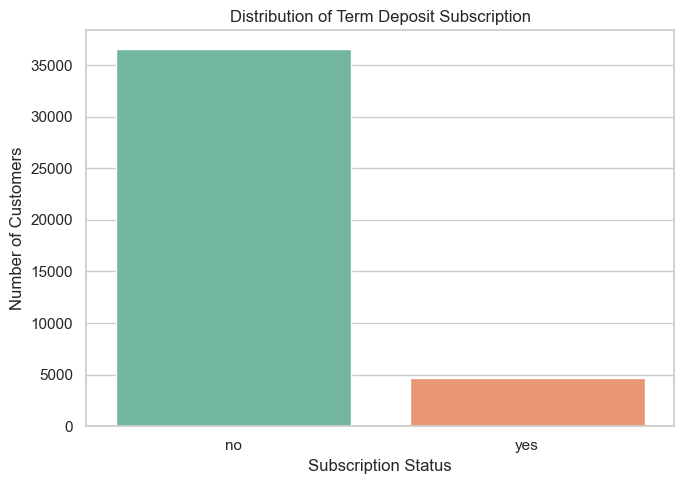

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="y",
    hue="y",
    order=["no", "yes"],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Term Deposit Subscription")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [22]:
# 3.3 Numerical Feature Analysis

numerical_features = df.select_dtypes(
    include=["number"]
).columns.tolist()

# Summary statistics
numerical_summary = df[numerical_features].describe().T

# Add median and skewness
numerical_summary["median"] = df[numerical_features].median()
numerical_summary["skewness"] = df[numerical_features].skew()

display(numerical_summary.round(3))

,count,mean,std,min,25%,50%,75%,max,median,skewness
age,41188.0,40.024,10.421,17.000,32.000,38.000,47.000,98.000,38.000,0.785
duration,41188.0,258.285,259.279,0.000,102.000,180.000,319.000,4918.000,180.000,3.263
campaign,41188.0,2.568,2.770,1.000,1.000,2.000,3.000,56.000,2.000,4.763
pdays,41188.0,962.475,186.911,0.000,999.000,999.000,999.000,999.000,999.000,-4.922
previous,41188.0,0.173,0.495,0.000,0.000,0.000,0.000,7.000,0.000,3.832
emp.var.rate,41188.0,0.082,1.571,-3.400,-1.800,1.100,1.400,1.400,1.100,-0.724
cons.price.idx,41188.0,93.576,0.579,92.201,93.075,93.749,93.994,94.767,93.749,-0.231
cons.conf.idx,41188.0,-40.503,4.628,-50.800,-42.700,-41.800,-36.400,-26.900,-41.800,0.303
euribor3m,41188.0,3.621,1.734,0.634,1.344,4.857,4.961,5.045,4.857,-0.709
nr.employed,41188.0,5167.036,72.252,4963.600,5099.100,5191.000,5228.100,5228.100,5191.000,-1.044


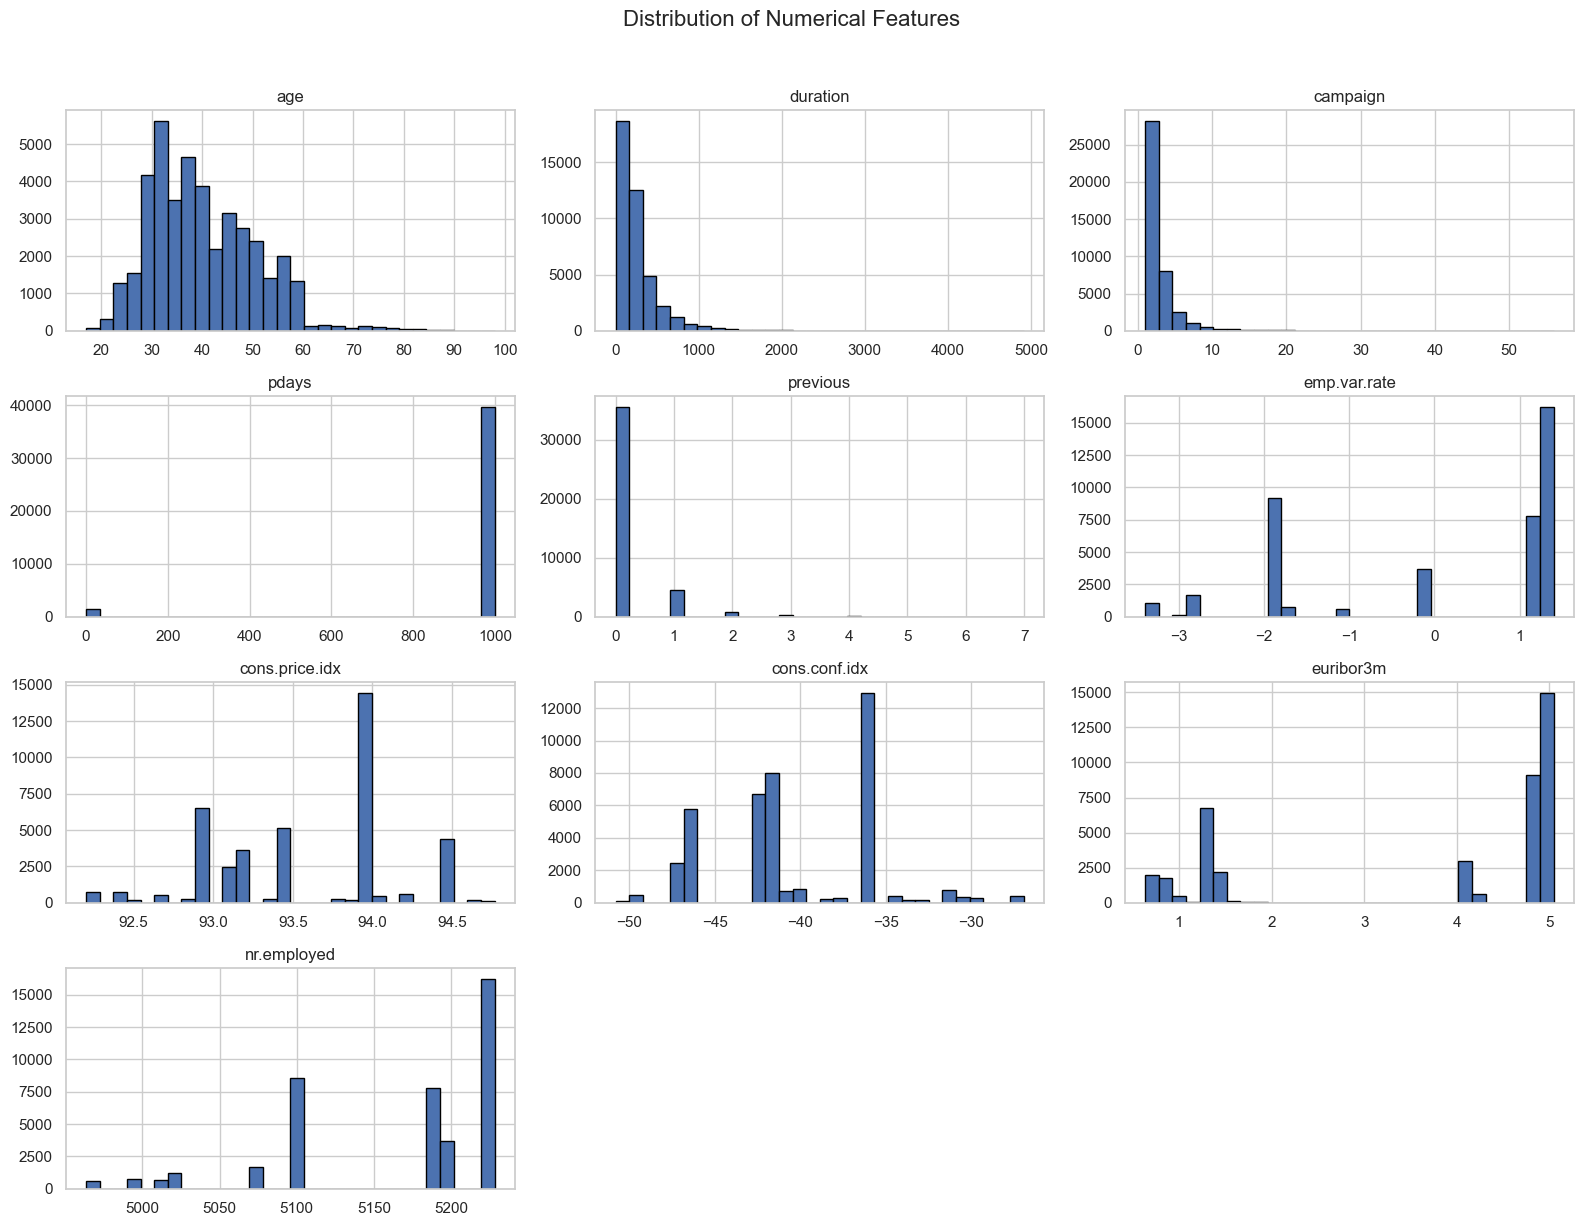

In [24]:
# Histograms of numerical features

df[numerical_features].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()

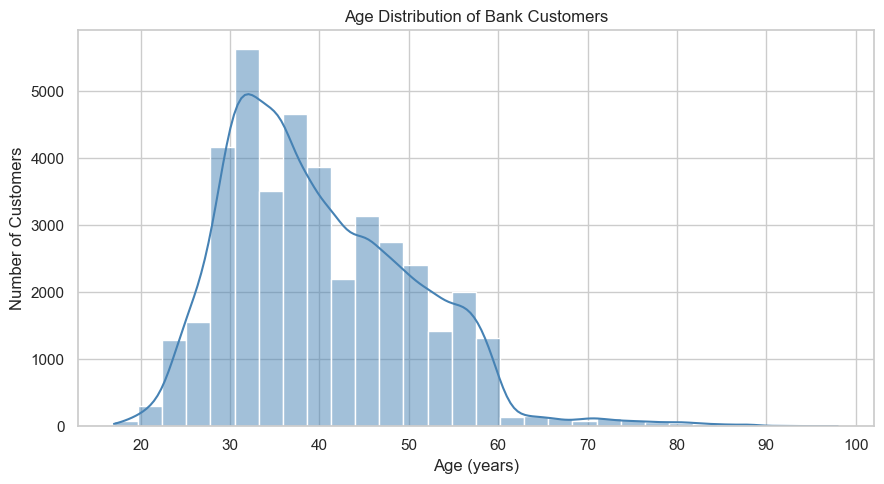

In [25]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="age",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("Age Distribution of Bank Customers")
plt.xlabel("Age (years)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

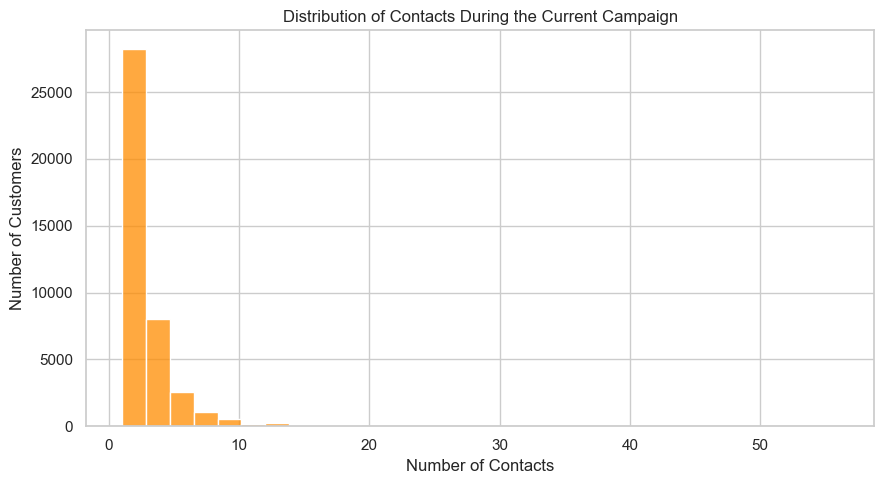

In [26]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="campaign",
    bins=30,
    color="darkorange"
)

plt.title("Distribution of Contacts During the Current Campaign")
plt.xlabel("Number of Contacts")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [27]:
print("Campaign contact frequency:")
display(df["campaign"].value_counts().sort_index().head(15))

print("\nCampaign summary:")
display(df["campaign"].describe())

Campaign contact frequency:


campaign
1     17642
2     10570
3      5341
4      2651
5      1599
6       979
7       629
8       400
9       283
10      225
11      177
12      125
13       92
14       69
15       51
Name: count, dtype: int64


Campaign summary:


count    41188.000000
mean         2.567593
std          2.770014
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         56.000000
Name: campaign, dtype: float64

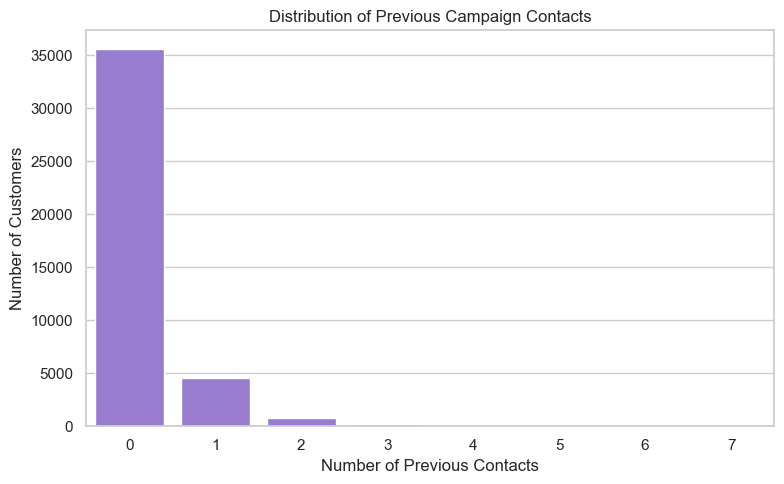

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="previous",
    color="mediumpurple"
)

plt.title("Distribution of Previous Campaign Contacts")
plt.xlabel("Number of Previous Contacts")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

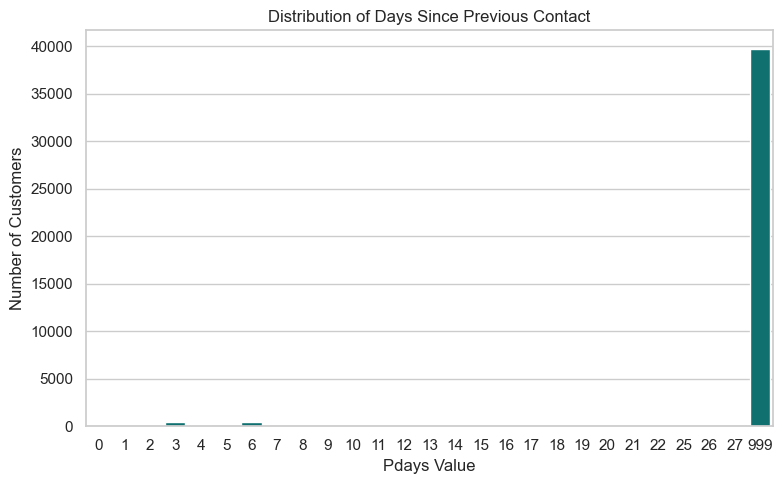

In [29]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="pdays",
    color="teal"
)

plt.title("Distribution of Days Since Previous Contact")
plt.xlabel("Pdays Value")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [30]:
# Count customers who were never previously contacted
never_contacted = (df["pdays"] == 999).sum()

# Count customers who were previously contacted
previously_contacted = (df["pdays"] != 999).sum()

print("Never previously contacted:", never_contacted)
print("Previously contacted:", previously_contacted)

print(
    "Percentage never previously contacted:",
    round(never_contacted / len(df) * 100, 2),
    "%"
)

Never previously contacted: 39673
Previously contacted: 1515
Percentage never previously contacted: 96.32 %


In [31]:
# Create an indicator for previous contact
df["previously_contacted"] = (df["pdays"] != 999).astype(int)

# Create a version of pdays where 999 becomes missing
df["pdays_clean"] = df["pdays"].replace(999, np.nan)

display(
    df[["pdays", "previously_contacted", "pdays_clean"]].head(10)
)

,pdays,previously_contacted,pdays_clean
0,999,0,NaN
1,999,0,NaN
2,999,0,NaN
3,999,0,NaN
4,999,0,NaN
5,999,0,NaN
6,999,0,NaN
7,999,0,NaN
8,999,0,NaN
9,999,0,NaN


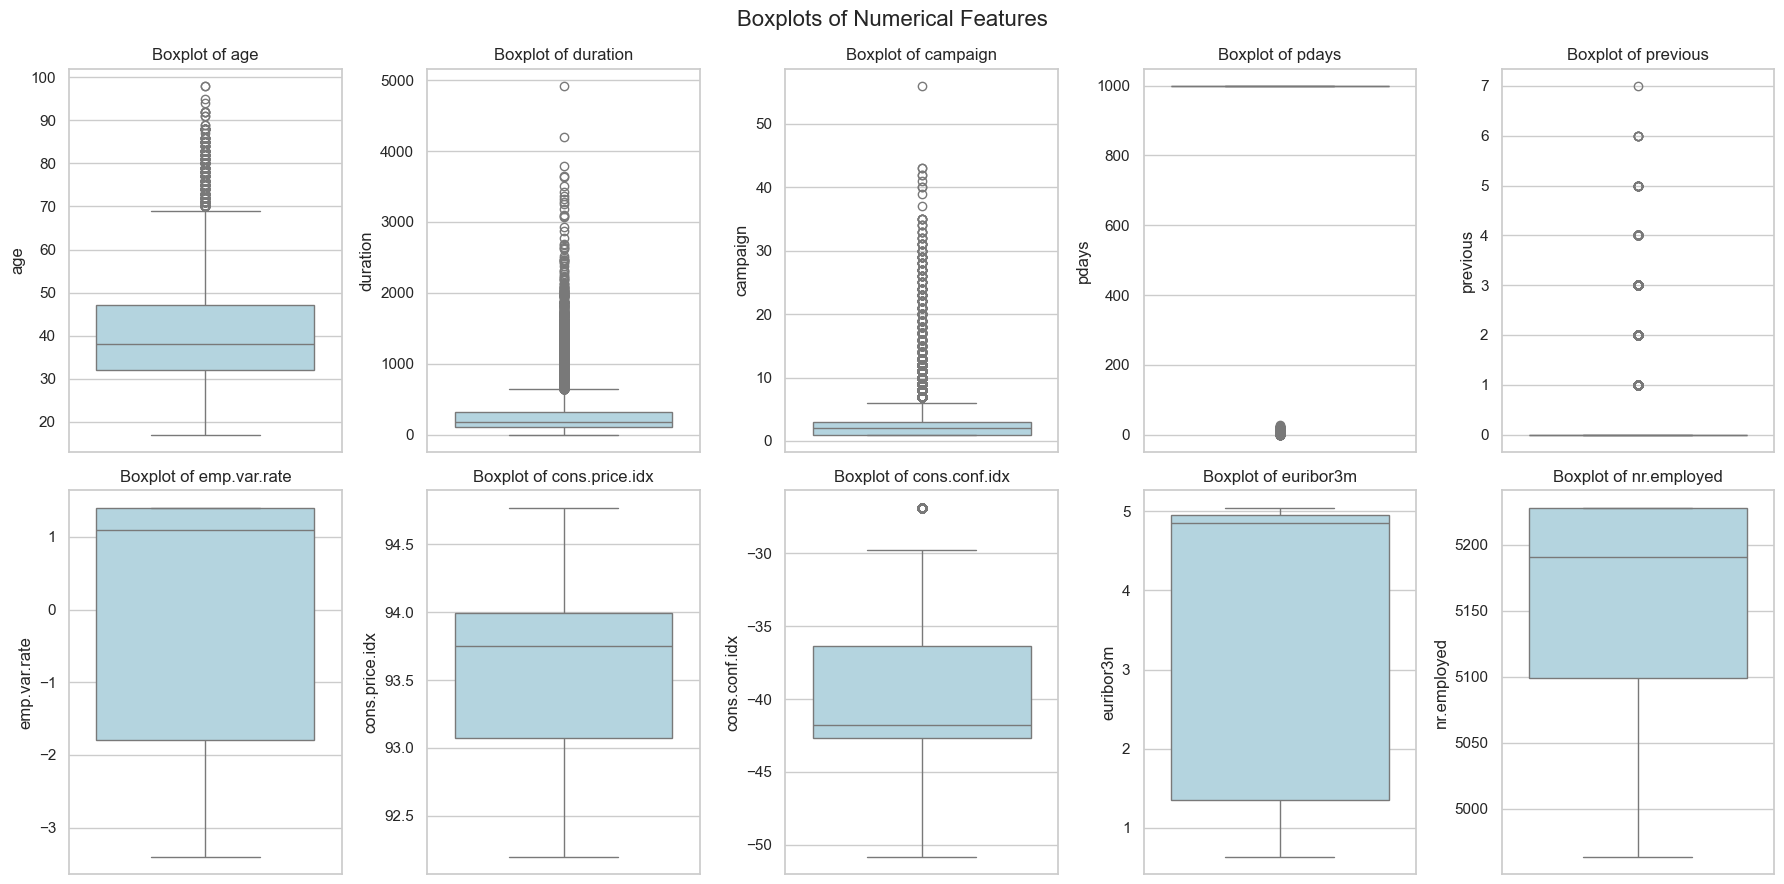

In [32]:
# Boxplots of numerical features
fig, axes = plt.subplots(2, 5, figsize=(18, 9))

for ax, col in zip(axes.flatten(), numerical_features):
    sns.boxplot(
        data=df,
        y=col,
        ax=ax,
        color="lightblue"
    )
    ax.set_title(f"Boxplot of {col}")
    ax.set_xlabel("")

plt.suptitle("Boxplots of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

In [33]:
outlier_results = []

for col in numerical_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": len(outliers),
        "Percentage": len(outliers) / len(df) * 100
    })

outlier_table = pd.DataFrame(outlier_results)

display(outlier_table.round(2))

,Feature,Lower Bound,Upper Bound,Potential Outliers,Percentage
0,age,9.50,69.50,469,1.14
1,duration,-223.50,644.50,2963,7.19
2,campaign,-2.00,6.00,2406,5.84
3,pdays,999.00,999.00,1515,3.68
4,previous,0.00,0.00,5625,13.66
5,emp.var.rate,-6.60,6.20,0,0.00
6,cons.price.idx,91.70,95.37,0,0.00
7,cons.conf.idx,-52.15,-26.95,447,1.09
8,euribor3m,-4.08,10.39,0,0.00
9,nr.employed,4905.60,5421.60,0,0.00


In [34]:
categorical_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "day_of_week",
    "poutcome"
]

In [35]:

# Generate frequency tables for all categorical features

for column in categorical_features:
    print(f"\nFrequency distribution for {column}:")
    print(df[column].value_counts())

    print("\nPercentages:")
    print(
        (df[column].value_counts(normalize=True) * 100)
        .round(2)
    )



Frequency distribution for job:
job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

Percentages:
job
admin.           25.30
blue-collar      22.47
technician       16.37
services          9.64
management        7.10
retired           4.18
entrepreneur      3.54
self-employed     3.45
housemaid         2.57
unemployed        2.46
student           2.12
unknown           0.80
Name: proportion, dtype: float64

Frequency distribution for marital:
marital
married     24928
single      11568
divorced     4612
unknown        80
Name: count, dtype: int64

Percentages:
marital
married     60.52
single      28.09
divorced    11.20
unknown      0.19
Name: proportion, dtype: float64

Frequency distribution for education:
education
university.degr

In [36]:

# Count unknown values in categorical features

unknown_counts = (
    df[categorical_features]
    .eq("unknown")
    .sum()
    .sort_values(ascending=False)
)

unknown_percentages = (
    df[categorical_features]
    .eq("unknown")
    .mean() * 100
).sort_values(ascending=False)

unknown_summary = pd.DataFrame({
    "Unknown Count": unknown_counts,
    "Unknown Percentage": unknown_percentages.round(2)
})

display(unknown_summary)


,Unknown Count,Unknown Percentage
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19
contact,0,0.00
month,0,0.00
day_of_week,0,0.00
poutcome,0,0.00


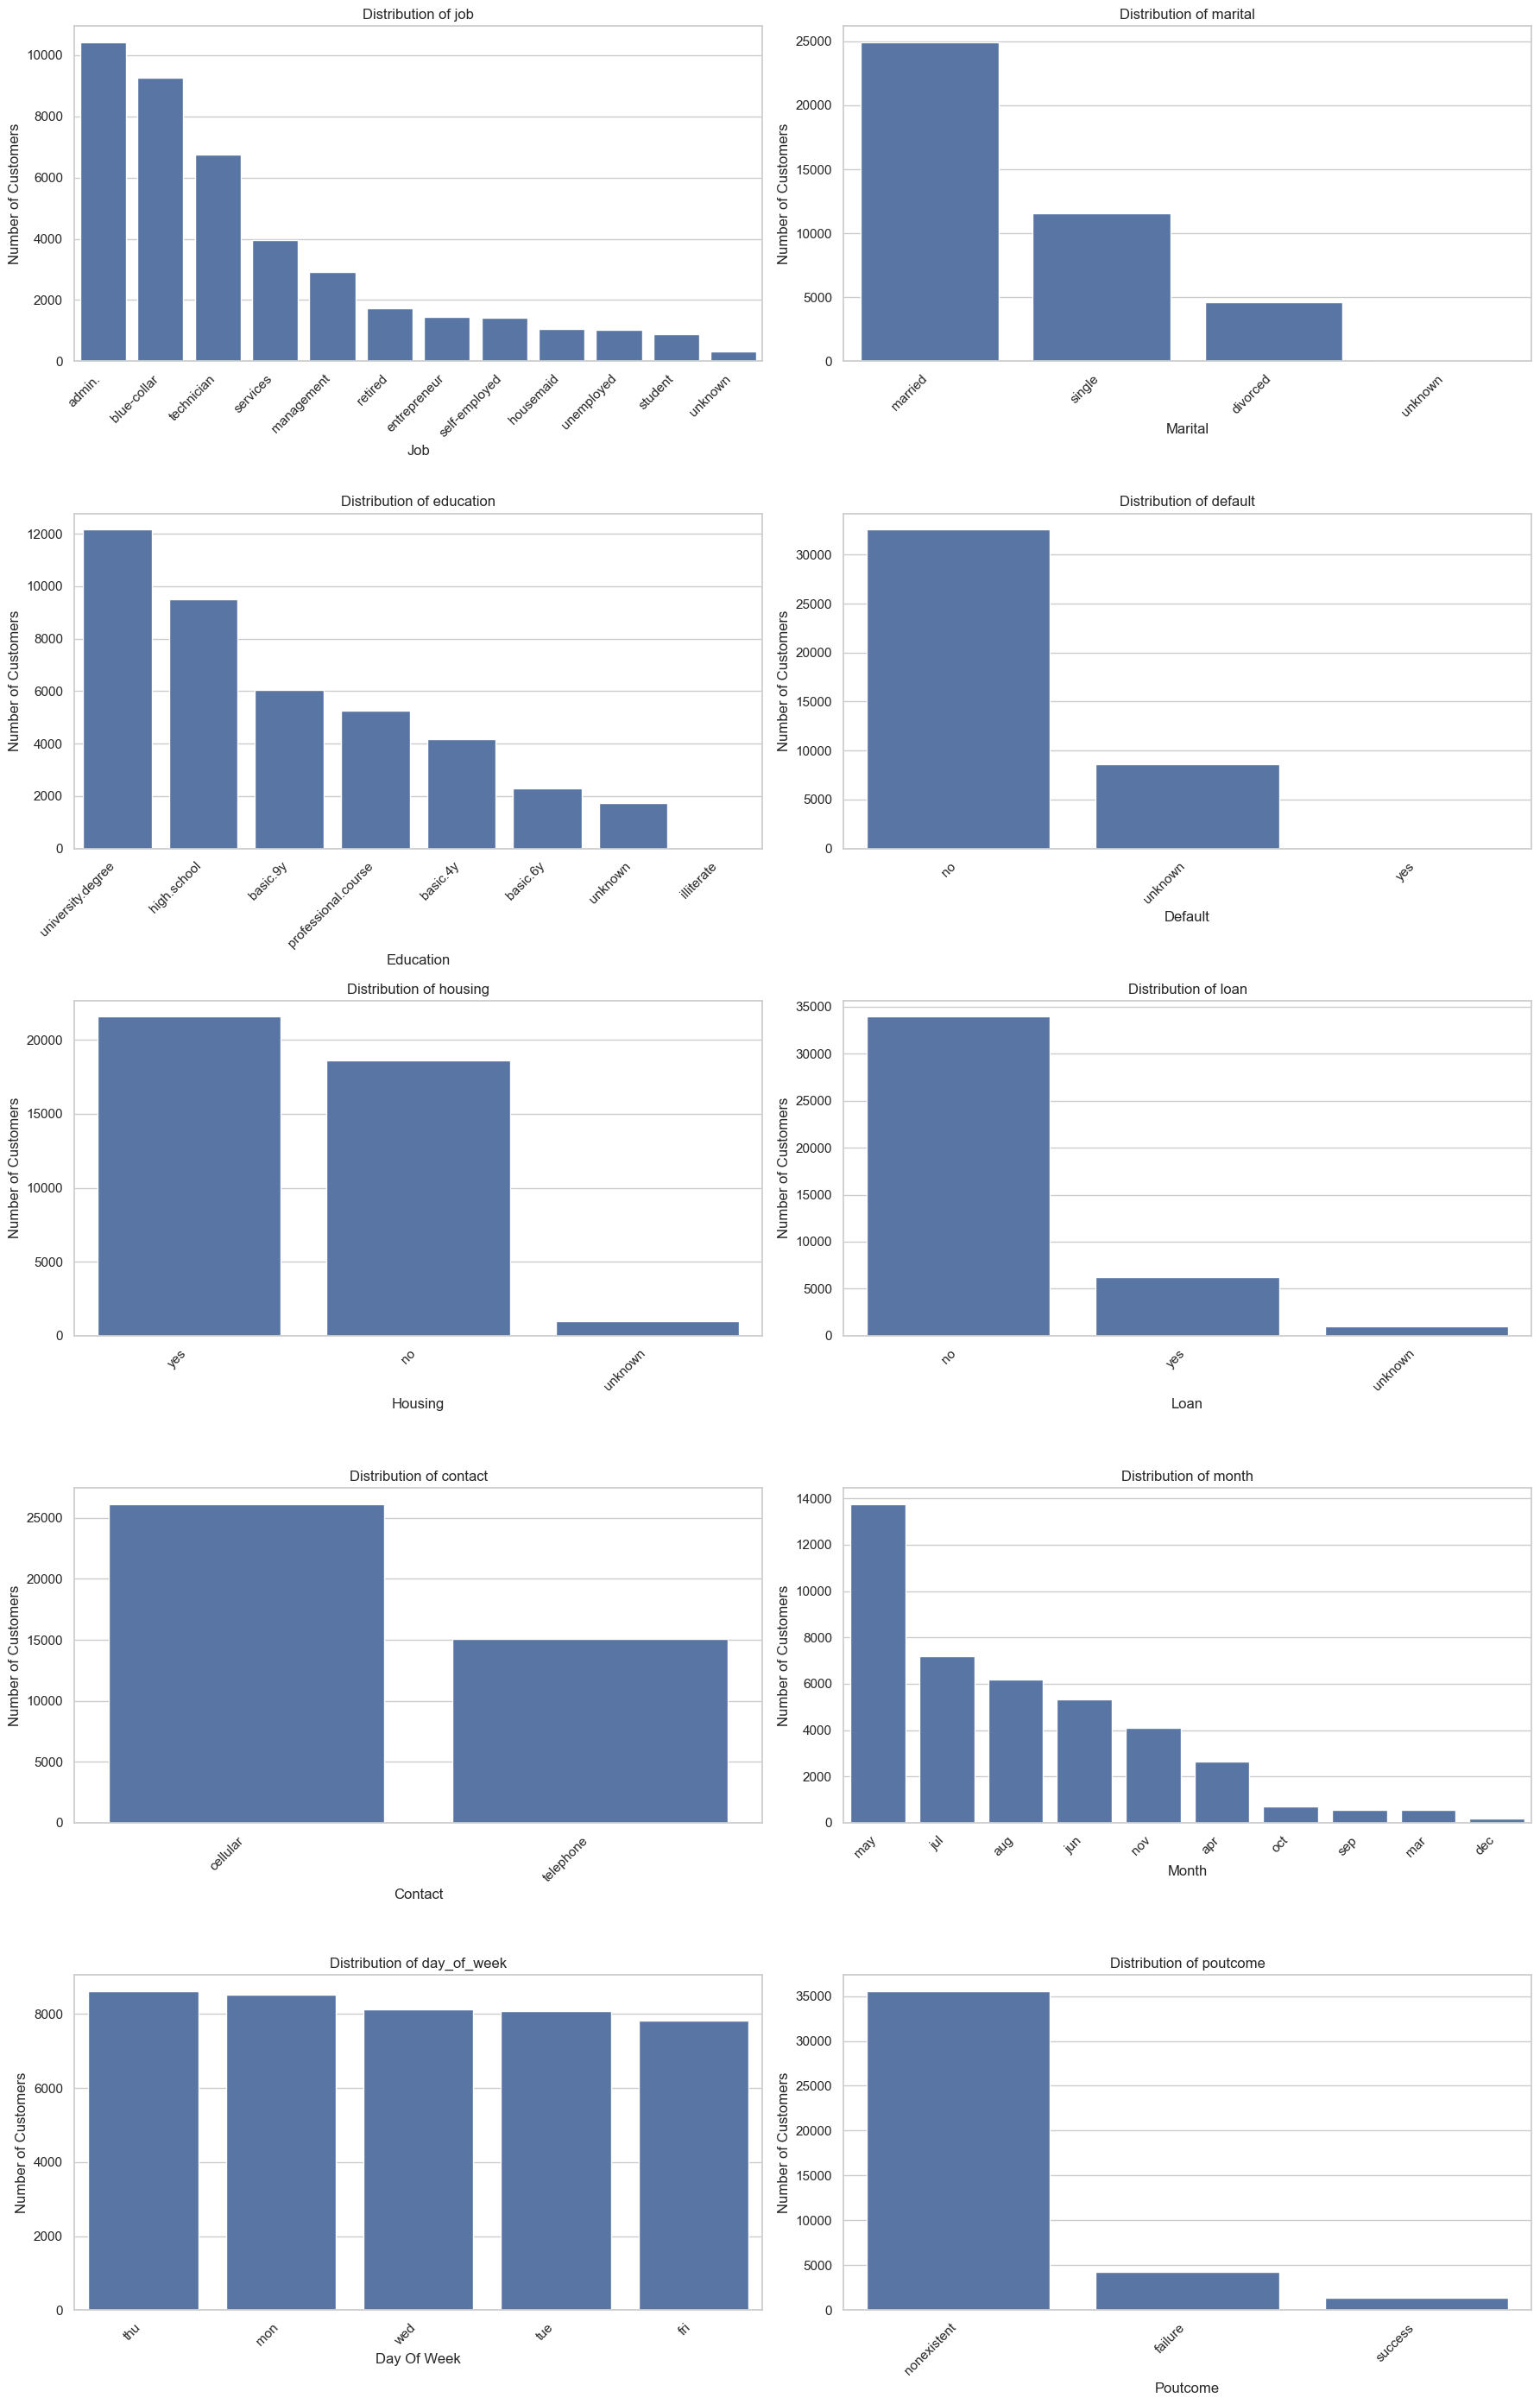

In [37]:


# Create a figure containing 10 subplots
fig, axes = plt.subplots(5, 2, figsize=(18, 28))

for i, column in enumerate(categorical_features):

    ax = axes[i // 2, i % 2]

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index,
        ax=ax
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of Customers")

    # Rotate category labels to improve readability
    ax.tick_params(axis="x", rotation=45)

    for label in ax.get_xticklabels():
        label.set_horizontalalignment("right")

plt.tight_layout()
plt.show()


In [38]:

def calculate_subscription_rate(data, feature):
    """
    Calculate customer counts and subscription rates
    for each category of a feature.
    """

    result = data.groupby(feature, observed=True)["y"].agg(
        total_customers="count",
        subscribers=lambda x: (x == "yes").sum()
    )

    result["subscription_rate"] = (
        result["subscribers"] /
        result["total_customers"] * 100
    )

    return result.sort_values(
        "subscription_rate",
        ascending=False
    ).round(2)


In [39]:
calculate_subscription_rate(df, "job")

,total_customers,subscribers,subscription_rate
job,,,
student,875,275,31.43
retired,1720,434,25.23
unemployed,1014,144,14.20
admin.,10422,1352,12.97
management,2924,328,11.22
unknown,330,37,11.21
technician,6743,730,10.83
self-employed,1421,149,10.49
housemaid,1060,106,10.00


,total_customers,subscribers,subscription_rate
age_group,,,
66+,619,290,46.85
17-25,1666,349,20.95
56-65,2963,451,15.22
26-35,14847,1740,11.72
46-55,8249,717,8.69
36-45,12844,1093,8.51


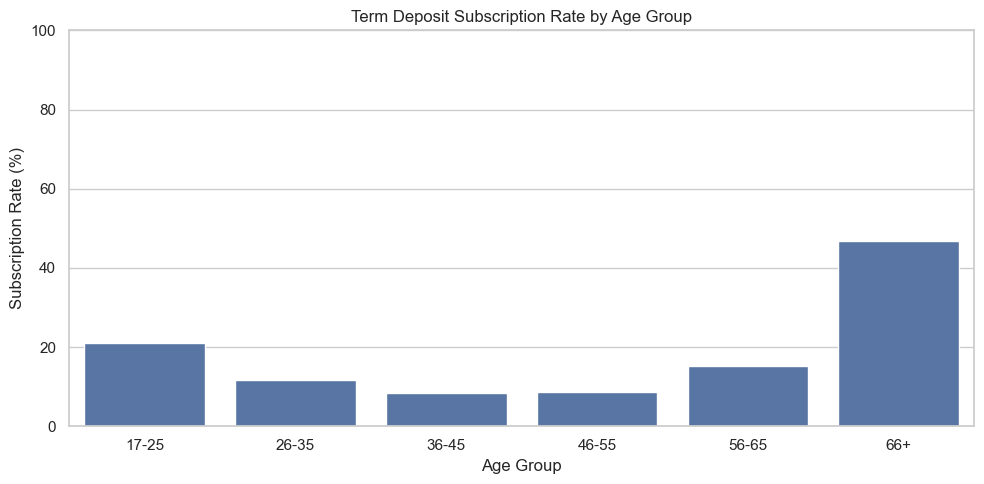

In [40]:

# Create age groups
df["age_group"] = pd.cut(
    df["age"],
    bins=[16, 25, 35, 45, 55, 65, 100],
    labels=["17-25", "26-35", "36-45", "46-55", "56-65", "66+"]
)

# Calculate subscription rates
age_rate = calculate_subscription_rate(df, "age_group")

display(age_rate)

# Visualize subscription rates
plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_rate.reset_index(),
    x="age_group",
    y="subscription_rate"
)

plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


,total_customers,subscribers,subscription_rate
job,,,
student,875,275,31.43
retired,1720,434,25.23
unemployed,1014,144,14.20
admin.,10422,1352,12.97
management,2924,328,11.22
unknown,330,37,11.21
technician,6743,730,10.83
self-employed,1421,149,10.49
housemaid,1060,106,10.00


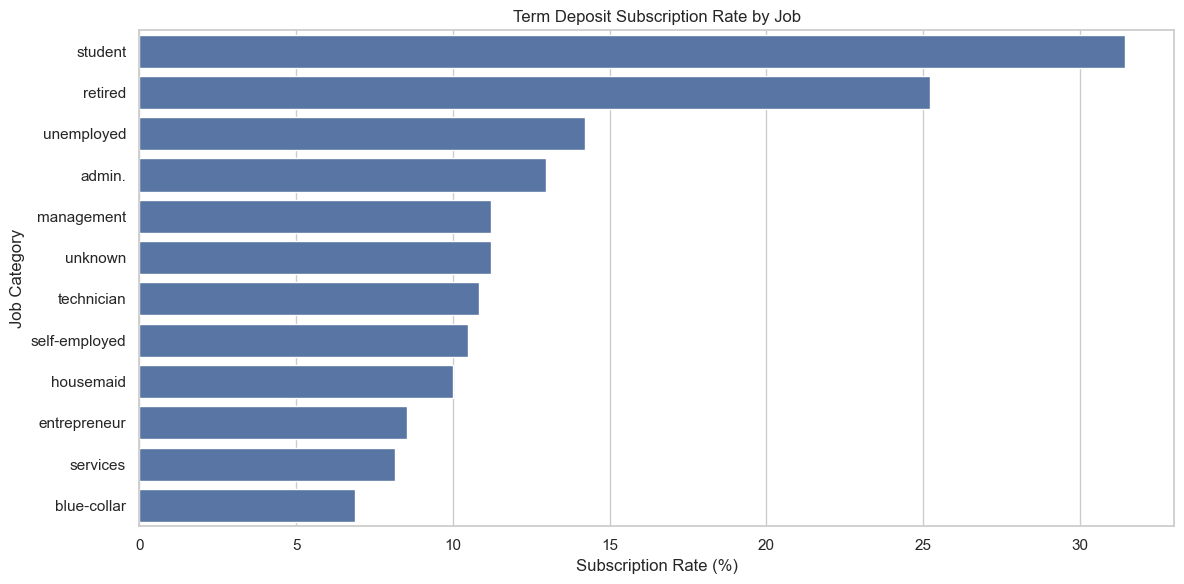

In [41]:

job_rate = calculate_subscription_rate(df, "job")

display(job_rate)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=job_rate.reset_index(),
    x="subscription_rate",
    y="job"
)

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job Category")
plt.tight_layout()
plt.show()


,total_customers,subscribers,subscription_rate
marital,,,
unknown,80,12,15.00
single,11568,1620,14.00
divorced,4612,476,10.32
married,24928,2532,10.16


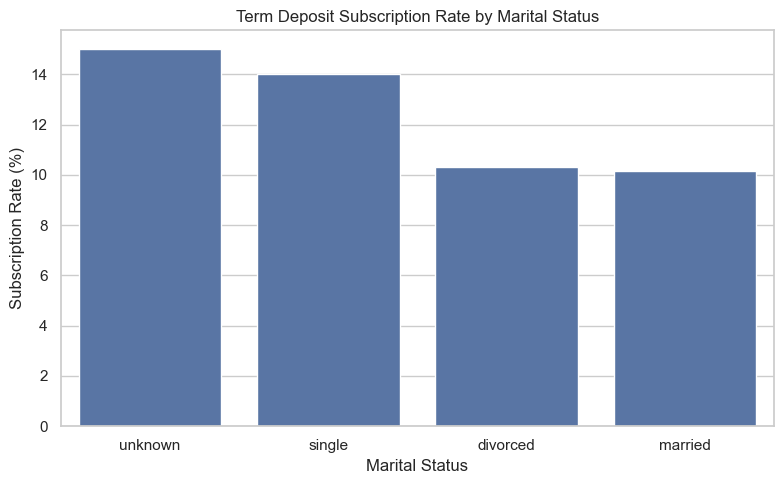

In [42]:

marital_rate = calculate_subscription_rate(df, "marital")

display(marital_rate)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=marital_rate.reset_index(),
    x="marital",
    y="subscription_rate"
)

plt.title("Term Deposit Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()


,total_customers,subscribers,subscription_rate
education,,,
illiterate,18,4,22.22
unknown,1731,251,14.50
university.degree,12168,1670,13.72
professional.course,5243,595,11.35
high.school,9515,1031,10.84
basic.4y,4176,428,10.25
basic.6y,2292,188,8.20
basic.9y,6045,473,7.82


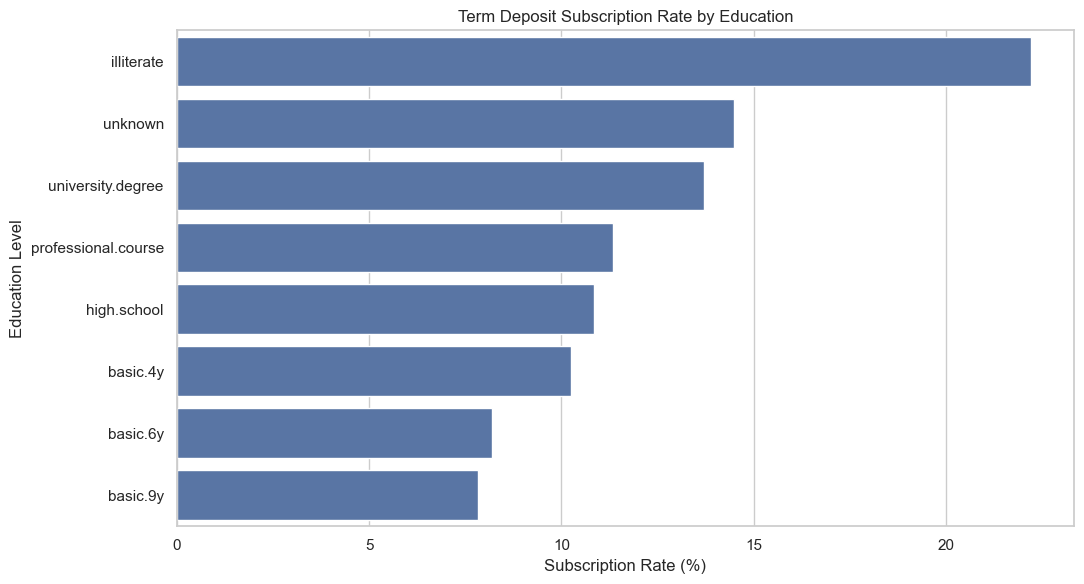

In [43]:

education_rate = calculate_subscription_rate(df, "education")

display(education_rate)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=education_rate.reset_index(),
    x="subscription_rate",
    y="education"
)

plt.title("Term Deposit Subscription Rate by Education")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Education Level")
plt.tight_layout()
plt.show()


,total_customers,subscribers,subscription_rate
contact,,,
cellular,26144,3853,14.74
telephone,15044,787,5.23


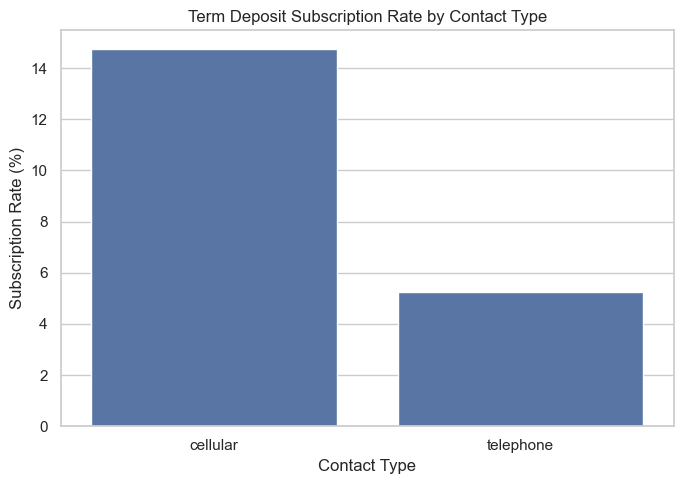

In [44]:

contact_rate = calculate_subscription_rate(df, "contact")

display(contact_rate)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=contact_rate.reset_index(),
    x="contact",
    y="subscription_rate"
)

plt.title("Term Deposit Subscription Rate by Contact Type")
plt.xlabel("Contact Type")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()


,total_customers,subscribers,subscription_rate
month,,,
mar,546,276,50.55
dec,182,89,48.90
sep,570,256,44.91
oct,718,315,43.87
apr,2632,539,20.48
aug,6178,655,10.60
jun,5318,559,10.51
nov,4101,416,10.14
jul,7174,649,9.05


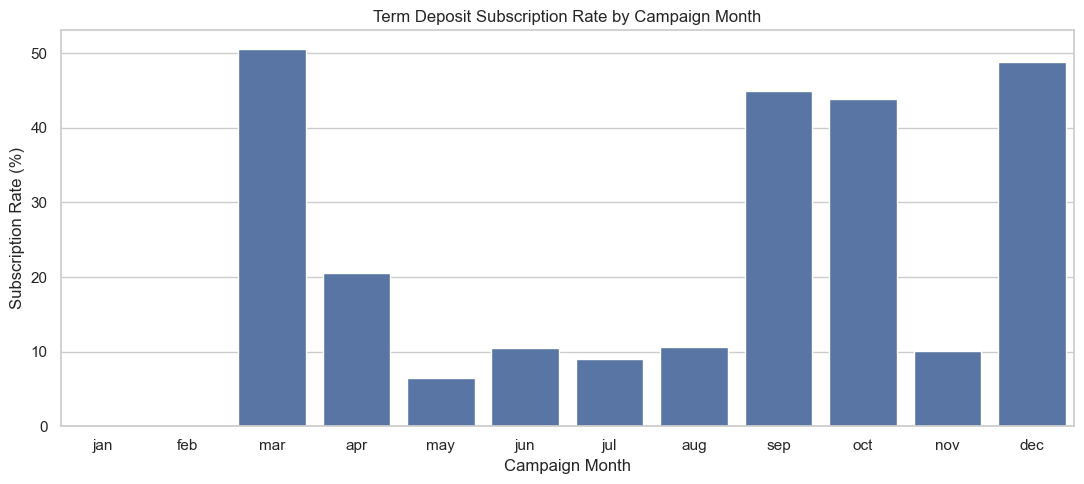

In [45]:

month_rate = calculate_subscription_rate(df, "month")

display(month_rate)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=month_rate.reset_index(),
    x="month",
    y="subscription_rate",
    order=[
        "jan", "feb", "mar", "apr", "may", "jun",
        "jul", "aug", "sep", "oct", "nov", "dec"
    ]
)

plt.title("Term Deposit Subscription Rate by Campaign Month")
plt.xlabel("Campaign Month")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()


,total_customers,subscribers,subscription_rate
poutcome,,,
success,1373,894,65.11
failure,4252,605,14.23
nonexistent,35563,3141,8.83


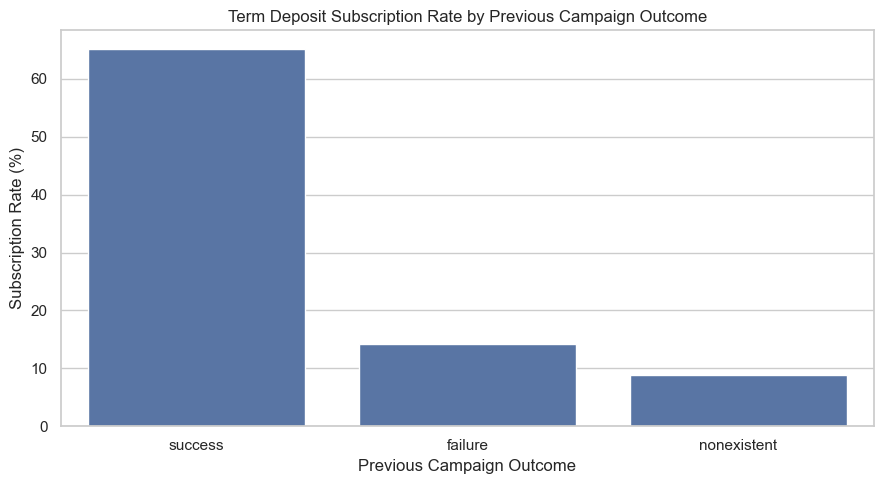

In [46]:

poutcome_rate = calculate_subscription_rate(df, "poutcome")

display(poutcome_rate)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=poutcome_rate.reset_index(),
    x="poutcome",
    y="subscription_rate"
)

plt.title("Term Deposit Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()


,total_customers,subscribers,subscription_rate
campaign_group,,,
1,17642,2300,13.04
2,10570,1211,11.46
3,5341,574,10.75
4-5,4250,369,8.68
6-10,2516,159,6.32
11+,869,27,3.11


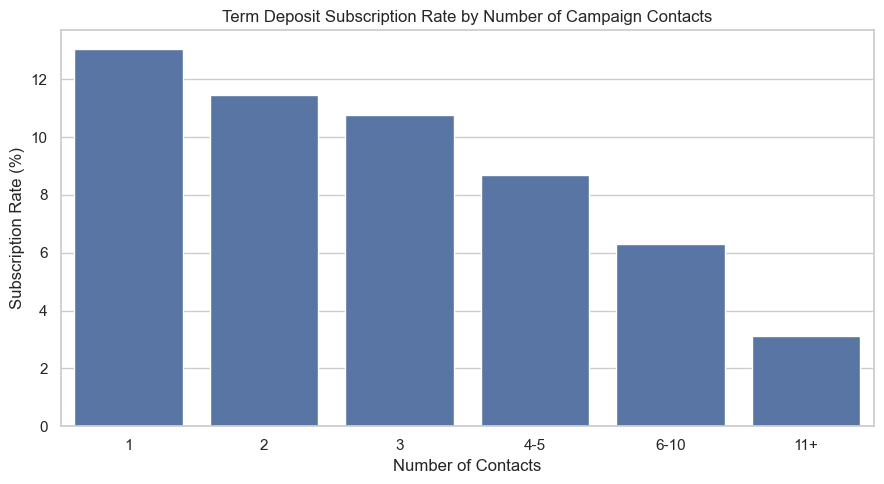

In [47]:

# Create groups based on the number of contacts
df["campaign_group"] = pd.cut(
    df["campaign"],
    bins=[0, 1, 2, 3, 5, 10, float("inf")],
    labels=["1", "2", "3", "4-5", "6-10", "11+"]
)

campaign_rate = calculate_subscription_rate(
    df, "campaign_group"
)

display(campaign_rate)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=campaign_rate.reset_index(),
    x="campaign_group",
    y="subscription_rate"
)

plt.title("Term Deposit Subscription Rate by Number of Campaign Contacts")
plt.xlabel("Number of Contacts")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()


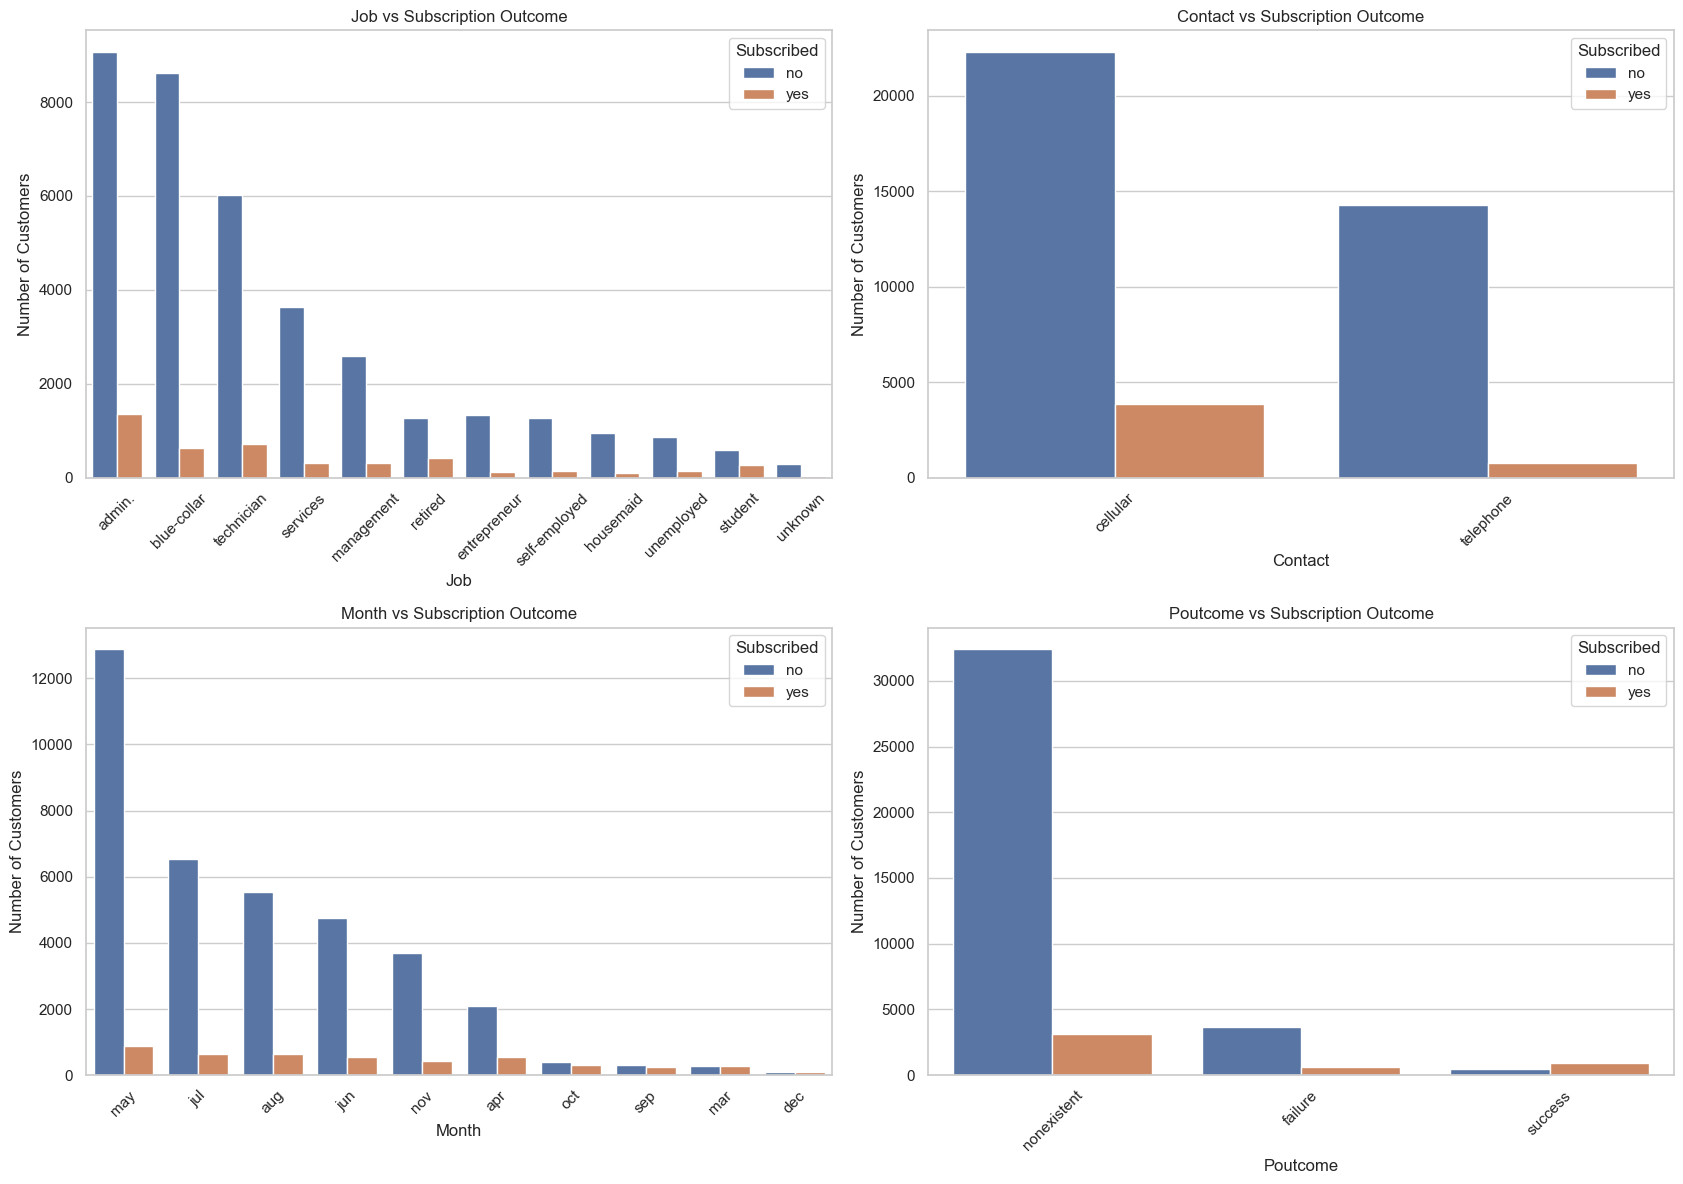

In [48]:

# Select important categorical features
selected_features = [
    "job",
    "contact",
    "month",
    "poutcome"
]

fig, axes = plt.subplots(2, 2, figsize=(17, 12))

for i, column in enumerate(selected_features):

    ax = axes[i // 2, i % 2]

    sns.countplot(
        data=df,
        x=column,
        hue="y",
        order=df[column].value_counts().index,
        ax=ax
    )

    ax.set_title(f"{column.title()} vs Subscription Outcome")
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Number of Customers")
    ax.tick_params(axis="x", rotation=45)

    ax.legend(title="Subscribed")

plt.tight_layout()
plt.show()


In [49]:

# Cross-tabulation: Job and subscription outcome

job_target_counts = pd.crosstab(
    df["job"],
    df["y"]
)

display(job_target_counts)

# Row percentages
job_target_percentages = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

display(job_target_percentages.round(2))


y,no,yes
job,,
admin.,9070,1352
blue-collar,8616,638
entrepreneur,1332,124
housemaid,954,106
management,2596,328
retired,1286,434
self-employed,1272,149
services,3646,323
student,600,275


y,no,yes
job,,
admin.,87.03,12.97
blue-collar,93.11,6.89
entrepreneur,91.48,8.52
housemaid,90.00,10.00
management,88.78,11.22
retired,74.77,25.23
self-employed,89.51,10.49
services,91.86,8.14
student,68.57,31.43


In [50]:
for column in [
    "marital",
    "education",
    "contact",
    "month",
    "poutcome"
]:
    print(f"\nCross-tabulation: {column} vs y")

    display(
        pd.crosstab(
            df[column],
            df["y"],
            normalize="index"
        ).mul(100).round(2)
    )


Cross-tabulation: marital vs y


y,no,yes
marital,,
divorced,89.68,10.32
married,89.84,10.16
single,86.00,14.00
unknown,85.00,15.00



Cross-tabulation: education vs y


y,no,yes
education,,
basic.4y,89.75,10.25
basic.6y,91.80,8.20
basic.9y,92.18,7.82
high.school,89.16,10.84
illiterate,77.78,22.22
professional.course,88.65,11.35
university.degree,86.28,13.72
unknown,85.50,14.50



Cross-tabulation: contact vs y


y,no,yes
contact,,
cellular,85.26,14.74
telephone,94.77,5.23



Cross-tabulation: month vs y


y,no,yes
month,,
apr,79.52,20.48
aug,89.40,10.60
dec,51.10,48.90
jul,90.95,9.05
jun,89.49,10.51
mar,49.45,50.55
may,93.57,6.43
nov,89.86,10.14
oct,56.13,43.87



Cross-tabulation: poutcome vs y


y,no,yes
poutcome,,
failure,85.77,14.23
nonexistent,91.17,8.83
success,34.89,65.11


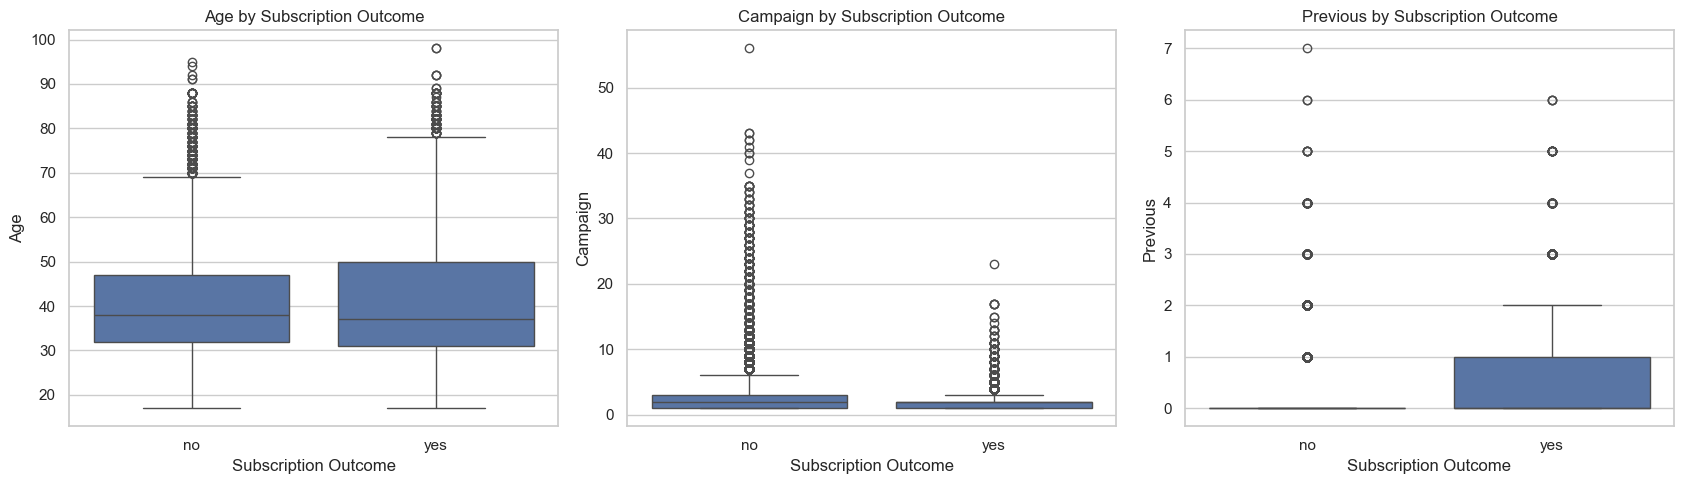

In [51]:
    
features_to_compare = [
    "age",
    "campaign",
    "previous"
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for i, column in enumerate(features_to_compare):

    sns.boxplot(
        data=df,
        x="y",
        y=column,
        ax=axes[i]
    )

    axes[i].set_title(f"{column.title()} by Subscription Outcome")
    axes[i].set_xlabel("Subscription Outcome")
    axes[i].set_ylabel(column.title())

plt.tight_layout()
plt.show()


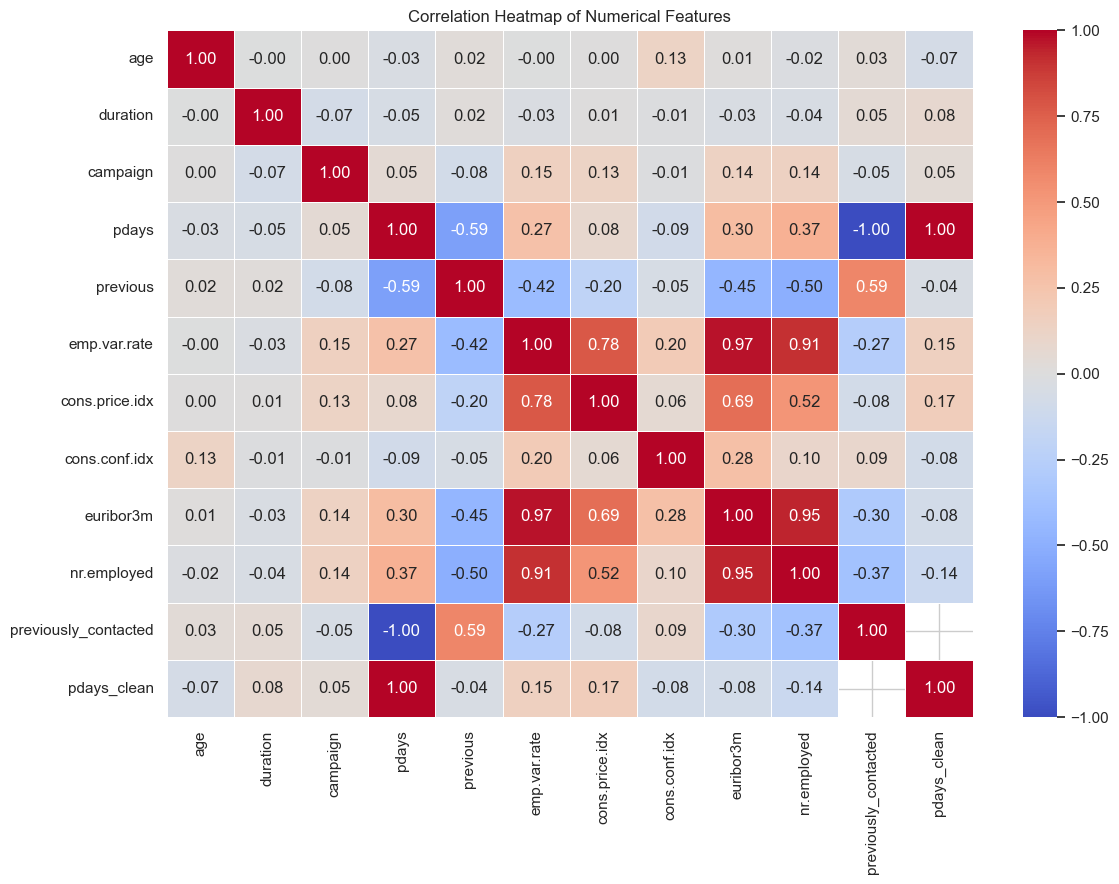

In [52]:
# Select numerical columns only
numerical_data = df.select_dtypes(include=["number"])

# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()

# Draw the heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [53]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate missing percentages
missing_percentage = (missing_values / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": missing_percentage
})

print(missing_summary)

                      Missing Count  Missing Percentage
age                               0            0.000000
job                               0            0.000000
marital                           0            0.000000
education                         0            0.000000
default                           0            0.000000
housing                           0            0.000000
loan                              0            0.000000
contact                           0            0.000000
month                             0            0.000000
day_of_week                       0            0.000000
duration                          0            0.000000
campaign                          0            0.000000
pdays                             0            0.000000
previous                          0            0.000000
poutcome                          0            0.000000
emp.var.rate                      0            0.000000
cons.price.idx                    0            0

In [54]:
# Find categorical columns
categorical_columns = df.select_dtypes(
    include=["object"]
).columns.drop("y")

# Count unknown values
unknown_counts = (
    df[categorical_columns] == "unknown"
).sum()

unknown_percentage = (
    unknown_counts / len(df)
) * 100

unknown_summary = pd.DataFrame({
    "Unknown Count": unknown_counts,
    "Unknown Percentage": unknown_percentage
})

unknown_summary = unknown_summary[
    unknown_summary["Unknown Count"] > 0
]

print(unknown_summary.sort_values(
    by="Unknown Count",
    ascending=False
))

           Unknown Count  Unknown Percentage
default             8597           20.872584
education           1731            4.202680
housing              990            2.403613
loan                 990            2.403613
job                  330            0.801204
marital               80            0.194231


In [55]:
unknown_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan"
]

for feature in unknown_features:

    print("\nFeature:", feature)

    unknown_data = df[df[feature] == "unknown"]

    total = len(unknown_data)

    subscribers = (
        unknown_data["y"] == "yes"
    ).sum()

    rate = (
        subscribers / total * 100
        if total > 0 else 0
    )

    print("Unknown records:", total)
    print("Subscribers:", subscribers)
    print("Subscription rate:", round(rate, 2), "%")


Feature: job
Unknown records: 330
Subscribers: 37
Subscription rate: 11.21 %

Feature: marital
Unknown records: 80
Subscribers: 12
Subscription rate: 15.0 %

Feature: education
Unknown records: 1731
Subscribers: 251
Subscription rate: 14.5 %

Feature: default
Unknown records: 8597
Subscribers: 443
Subscription rate: 5.15 %

Feature: housing
Unknown records: 990
Subscribers: 107
Subscription rate: 10.81 %

Feature: loan
Unknown records: 990
Subscribers: 107
Subscription rate: 10.81 %


In [56]:
# Count duplicate rows, excluding the first occurrence
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 12


In [57]:
# Count every row that belongs to a duplicate group
all_duplicate_rows = df.duplicated(keep=False).sum()

print("Rows belonging to duplicate groups:", all_duplicate_rows)

Rows belonging to duplicate groups: 24


In [58]:
# Display all rows belonging to duplicate groups
duplicate_records = df[df.duplicated(keep=False)]

print("Duplicate records shape:", duplicate_records.shape)

# Display the duplicate records
duplicate_records.sort_values(
    by=list(df.columns)
)

Duplicate records shape: (24, 25)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,previously_contacted,pdays_clean,age_group,campaign_group
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no,0,NaN,17-25,1
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,114,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no,0,NaN,17-25,1
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no,0,NaN,26-35,2
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,331,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no,0,NaN,26-35,2
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no,0,NaN,26-35,1
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,128,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no,0,NaN,26-35,1
32505,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no,0,NaN,26-35,4-5
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,348,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no,0,NaN,26-35,4-5
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no,0,NaN,36-45,1
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,88,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no,0,NaN,36-45,1


In [59]:
# Check the target distribution among duplicate-group rows
print(
    duplicate_records["y"].value_counts()
)

y
no     22
yes     2
Name: count, dtype: int64


In [60]:
# Create a cleaned copy of the dataset
df_clean = df.drop_duplicates().copy()

# Check the new dataset dimensions
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

# Verify that no exact duplicates remain
print(
    "Remaining duplicate rows:",
    df_clean.duplicated().sum()
)

# Number of removed rows
print(
    "Rows removed:",
    len(df) - len(df_clean)
)

Original dataset shape: (41188, 25)
Cleaned dataset shape: (41176, 25)
Remaining duplicate rows: 0
Rows removed: 12


In [62]:
print("Target distribution before removing duplicates:")
print(df["y"].value_counts())

print("Target distribution before removing duplicates:")
print(
    (df["y"].value_counts(normalize=True) * 100).round(2)
)

print("\nTarget distribution after removing duplicates:")
print(df_clean["y"].value_counts())

print("\nTarget percentages after removing duplicates:")
print(
    (df_clean["y"].value_counts(normalize=True) * 100).round(2)
)

Target distribution before removing duplicates:
y
no     36548
yes     4640
Name: count, dtype: int64
Target distribution before removing duplicates:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

Target distribution after removing duplicates:
y
no     36537
yes     4639
Name: count, dtype: int64

Target percentages after removing duplicates:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


In [63]:
# Select numerical columns
numerical_columns = df_clean.select_dtypes(
    include=["number"]
).columns

outlier_results = []

for column in numerical_columns:

    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (
            len(outliers) / len(df_clean)
        ) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

print(outlier_summary.round(2))

                 Feature       Q1       Q3  Lower Bound  Upper Bound  \
0                    age    32.00    47.00         9.50        69.50   
1               duration   102.00   319.00      -223.50       644.50   
2               campaign     1.00     3.00        -2.00         6.00   
3                  pdays   999.00   999.00       999.00       999.00   
4               previous     0.00     0.00         0.00         0.00   
5           emp.var.rate    -1.80     1.40        -6.60         6.20   
6         cons.price.idx    93.08    93.99        91.70        95.37   
7          cons.conf.idx   -42.70   -36.40       -52.15       -26.95   
8              euribor3m     1.34     4.96        -4.08        10.39   
9            nr.employed  5099.10  5228.10      4905.60      5421.60   
10  previously_contacted     0.00     0.00         0.00         0.00   
11           pdays_clean     3.00     7.00        -3.00        13.00   

    Outlier Count  Outlier Percentage  
0             468      

In [64]:
print("Minimum age:", df_clean["age"].min())
print("Maximum age:", df_clean["age"].max())

print("\nCustomers younger than 18:")
print((df_clean["age"] < 18).sum())

print("\nCustomers older than 90:")
print((df_clean["age"] > 90).sum())

Minimum age: 17
Maximum age: 98

Customers younger than 18:
5

Customers older than 90:
10


In [65]:
print("Minimum campaign contacts:", df_clean["campaign"].min())
print("Maximum campaign contacts:", df_clean["campaign"].max())

print(
    "Customers contacted more than 10 times:",
    (df_clean["campaign"] > 10).sum()
)

print(
    "Customers contacted more than 20 times:",
    (df_clean["campaign"] > 20).sum()
)

Minimum campaign contacts: 1
Maximum campaign contacts: 56
Customers contacted more than 10 times: 869
Customers contacted more than 20 times: 157


In [66]:
print(
    df_clean["previous"].value_counts().sort_index()
)

previous
0    35551
1     4561
2      754
3      216
4       70
5       18
6        5
7        1
Name: count, dtype: int64


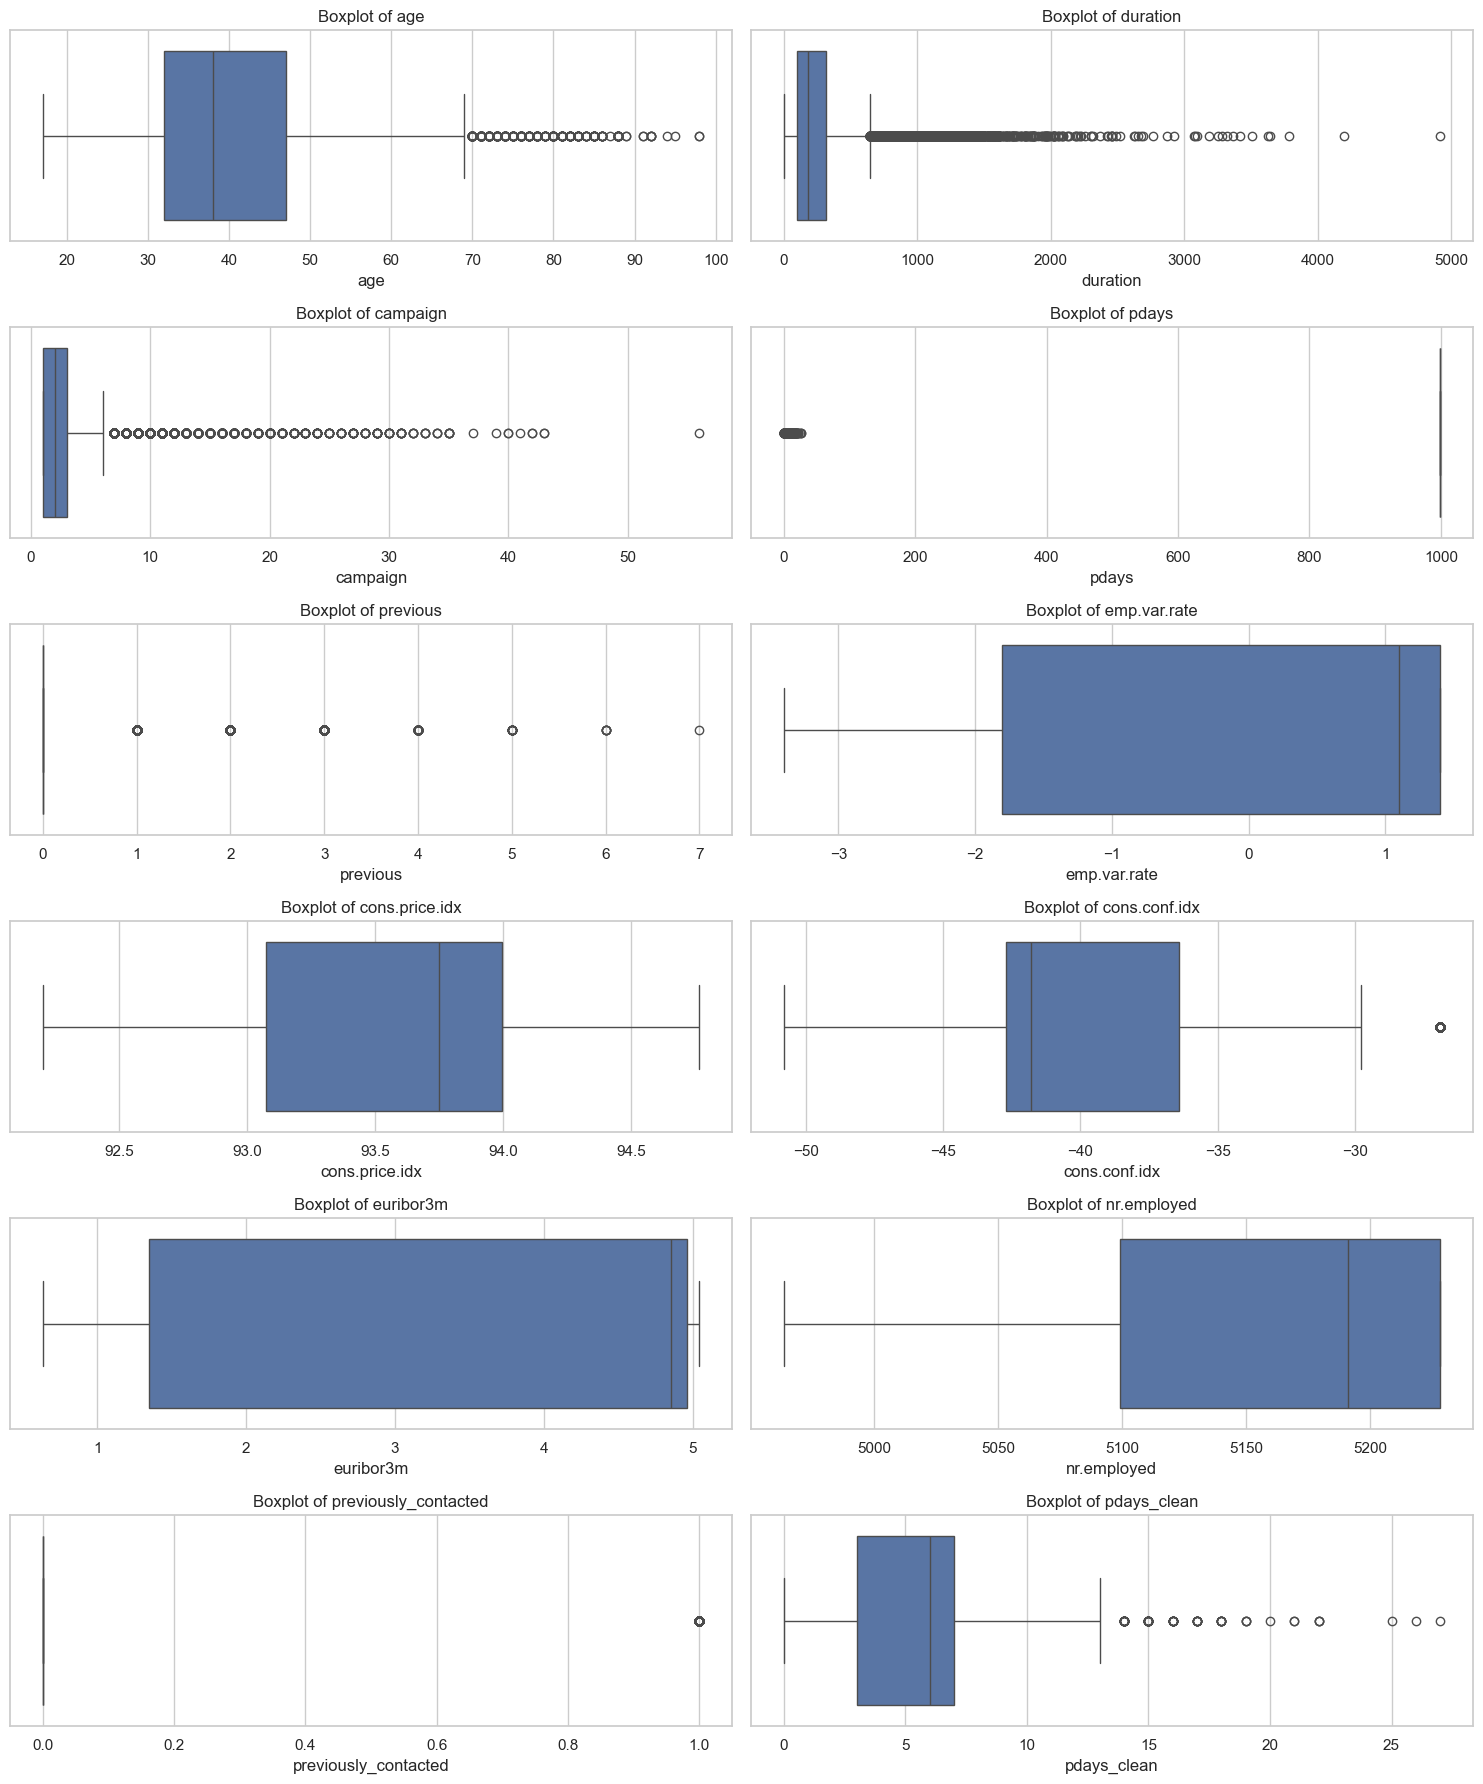

In [109]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = df_clean.select_dtypes(include=["number"]).columns

n_cols = 2
n_rows = math.ceil(len(numerical_columns) / n_cols)

plt.figure(figsize=(15, 3 * n_rows))

for i, column in enumerate(numerical_columns, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.boxplot(x=df_clean[column])
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)

plt.tight_layout()
plt.show()

In [69]:
expected_categories = {
    "job": [
        "admin.", "blue-collar", "entrepreneur",
        "housemaid", "management", "retired",
        "self-employed", "services", "student",
        "technician", "unemployed", "unknown"
    ],

    "marital": [
        "divorced", "married", "single", "unknown"
    ],

    "education": [
        "basic.4y", "basic.6y", "basic.9y",
        "high.school", "illiterate",
        "professional.course", "university.degree",
        "unknown"
    ],

    "default": ["no", "yes", "unknown"],

    "housing": ["no", "yes", "unknown"],

    "loan": ["no", "yes", "unknown"],

    "contact": ["cellular", "telephone"],

    "month": [
        "jan", "feb", "mar", "apr", "may", "jun",
        "jul", "aug", "sep", "oct", "nov", "dec"
    ],

    "day_of_week": ["mon", "tue", "wed", "thu", "fri"],

    "poutcome": ["failure", "nonexistent", "success"],

    "y": ["no", "yes"]
}

for column, expected in expected_categories.items():

    actual = set(df_clean[column].unique())

    unexpected = actual - set(expected)

    print(f"\n{column}")
    print("Unexpected values:", unexpected)


job
Unexpected values: set()

marital
Unexpected values: set()

education
Unexpected values: set()

default
Unexpected values: set()

housing
Unexpected values: set()

loan
Unexpected values: set()

contact
Unexpected values: set()

month
Unexpected values: set()

day_of_week
Unexpected values: set()

poutcome
Unexpected values: set()

y
Unexpected values: set()


In [70]:
# Create a binary feature indicating whether the customer
# was previously contacted.

df_clean["previously_contacted"] = (
    df_clean["pdays"] != 999
).astype(int)


# Replace the special value 999 with NaN
# to represent the absence of a previous contact.

df_clean["pdays_clean"] = df_clean["pdays"].replace(
    999, np.nan
)

In [71]:
# Count customers according to previous contact status
print(df_clean["previously_contacted"].value_counts())

# Display statistics for actual previous-contact days
print(df_clean["pdays_clean"].describe())

# Inspect the original and transformed columns
print(
    df_clean[
        ["pdays", "pdays_clean", "previously_contacted"]
    ].head(10)
)

previously_contacted
0    39661
1     1515
Name: count, dtype: int64
count    1515.000000
mean        6.014521
std         3.824906
min         0.000000
25%         3.000000
50%         6.000000
75%         7.000000
max        27.000000
Name: pdays_clean, dtype: float64
   pdays  pdays_clean  previously_contacted
0    999          NaN                     0
1    999          NaN                     0
2    999          NaN                     0
3    999          NaN                     0
4    999          NaN                     0
5    999          NaN                     0
6    999          NaN                     0
7    999          NaN                     0
8    999          NaN                     0
9    999          NaN                     0


In [73]:
df_clean.head(10)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,previously_contacted,pdays_clean,age_group,campaign_group
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,NaN,56-65,1
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,NaN,56-65,1
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,NaN,36-45,1
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,NaN,36-45,1
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,NaN,56-65,1
5,45,services,married,basic.9y,unknown,no,no,telephone,may,mon,198,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,NaN,36-45,1
6,59,admin.,married,professional.course,no,no,no,telephone,may,mon,139,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,NaN,56-65,1
7,41,blue-collar,married,unknown,unknown,no,no,telephone,may,mon,217,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,NaN,36-45,1
8,24,technician,single,professional.course,no,yes,no,telephone,may,mon,380,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,NaN,17-25,1
9,25,services,single,high.school,no,yes,no,telephone,may,mon,50,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no,0,NaN,17-25,1


In [74]:
# Columns that must not be used as predictive features
excluded_features = ["y", "duration", "pdays"]

# All remaining original features
classification_features = [
    col for col in df_clean.columns
    if col not in excluded_features
]

# Add the transformed pdays features
classification_features += [
    "previously_contacted",
    "pdays_clean"
]

print("Number of classification features:",
      len(classification_features))

print(classification_features)

Number of classification features: 24
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'pdays_clean', 'age_group', 'campaign_group', 'previously_contacted', 'pdays_clean']


In [77]:
# Use the feature list defined in Section 4.5
X = df_clean[classification_features].copy()

# Separate categorical and numerical features
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'age_group', 'campaign_group']

Numerical features:
['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'pdays_clean', 'previously_contacted', 'pdays_clean']


In [78]:
categorical_encoder = OneHotEncoder(
    handle_unknown="ignore"
)

In [79]:
from sklearn.preprocessing import StandardScaler

numerical_scaler = StandardScaler()

In [80]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [81]:
from sklearn.model_selection import train_test_split

# Separate input features from the target
X = df_clean[classification_features].copy()
y = df_clean["y"].copy()

# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the sizes of the resulting sets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))

Training features: (32940, 24)
Testing features: (8236, 24)

Training target distribution:
y
no     29229
yes     3711
Name: count, dtype: int64
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

Testing target distribution:
y
no     7308
yes     928
Name: count, dtype: int64
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


In [86]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing
tree_numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
tree_categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
tree_preprocessor = ColumnTransformer(transformers=[
    ("num", tree_numerical_pipeline, numerical_features),
    ("cat", tree_categorical_pipeline, categorical_features)
])

In [89]:
# Exclude the target, duration, and original pdays column
excluded_features = ["y", "duration", "pdays"]

classification_features = [
    col for col in df_clean.columns
    if col not in excluded_features
]

# Check that the feature names are unique
print("Number of features:", len(classification_features))
print("Number of unique features:", len(set(classification_features)))
print("Duplicate feature names:",
      [col for col in classification_features
       if classification_features.count(col) > 1])

Number of features: 22
Number of unique features: 22
Duplicate feature names: []


In [91]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df_clean[classification_features].copy()
y = df_clean["y"].copy()

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (32940, 22)
Testing features: (8236, 22)


In [92]:
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'pdays_clean']

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'age_group', 'campaign_group']


In [93]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

# Numerical preprocessing: median imputation
tree_numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing: most-frequent imputation + One-Hot Encoding
tree_categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
tree_preprocessor = ColumnTransformer(transformers=[
    ("num", tree_numerical_pipeline, numerical_features),
    ("cat", tree_categorical_pipeline, categorical_features)
])

# Create the complete Decision Tree pipeline
decision_tree_model = Pipeline(steps=[
    ("preprocessor", tree_preprocessor),
    ("classifier", DecisionTreeClassifier(
        criterion="gini",
        max_depth=5,
        min_samples_leaf=20,
        random_state=42
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [94]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predict the test set
y_pred_tree = decision_tree_model.predict(X_test)

# Get the probability of the positive class ("yes")
yes_index = list(decision_tree_model.classes_).index("yes")
y_prob_tree = decision_tree_model.predict_proba(X_test)[:, yes_index]

# Display evaluation results
print("Accuracy:",
      accuracy_score(y_test, y_pred_tree))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_tree,
    labels=["no", "yes"]
))

print("\nROC-AUC:",
      roc_auc_score(
          (y_test == "yes").astype(int),
          y_prob_tree
      ))

Accuracy: 0.9014084507042254

Classification Report:
              precision    recall  f1-score   support

          no       0.91      0.98      0.95      7308
         yes       0.66      0.26      0.37       928

    accuracy                           0.90      8236
   macro avg       0.79      0.62      0.66      8236
weighted avg       0.88      0.90      0.88      8236


Confusion Matrix:
[[7185  123]
 [ 689  239]]

ROC-AUC: 0.790910011819829


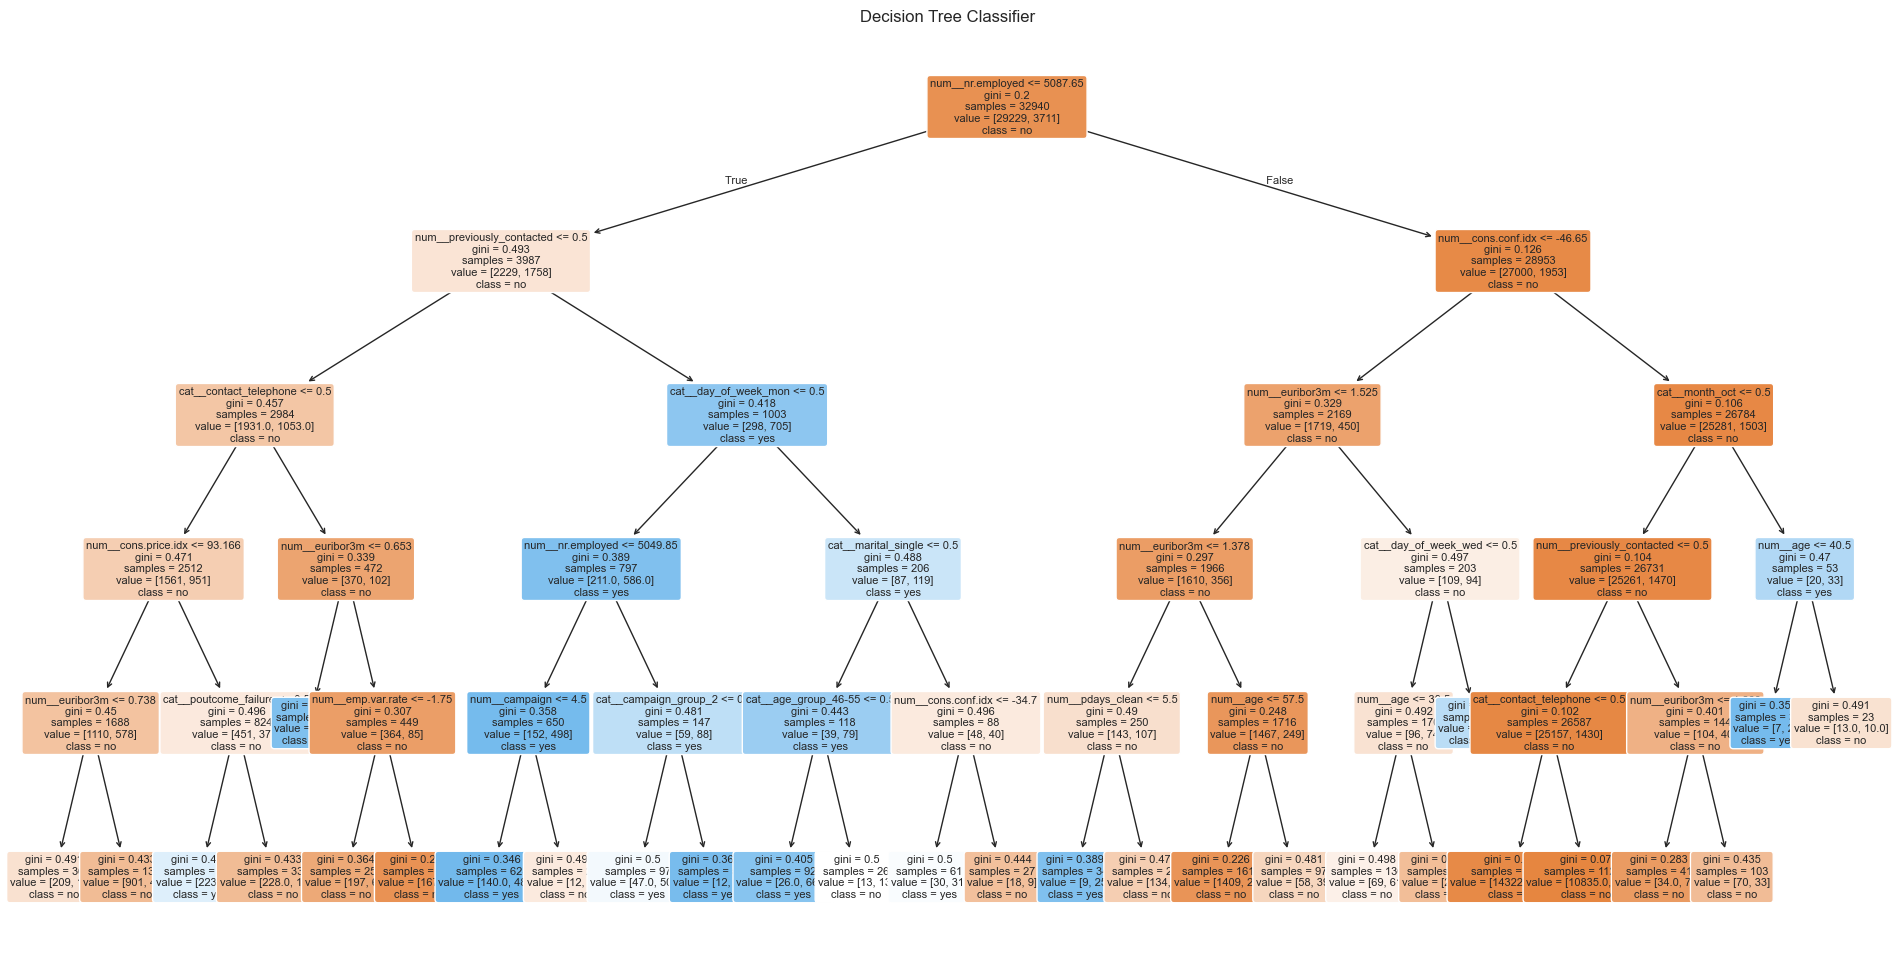

In [95]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Get the trained classifier from the pipeline
trained_tree = decision_tree_model.named_steps["classifier"]

# Get the names of the transformed features
feature_names = (
    decision_tree_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

plt.figure(figsize=(24, 12))

plot_tree(
    trained_tree,
    feature_names=feature_names,
    class_names=trained_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier")
plt.show()

In [96]:
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": trained_tree.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

                      Feature  Importance
7            num__nr.employed    0.649436
8   num__previously_contacted    0.130827
5          num__cons.conf.idx    0.061406
6              num__euribor3m    0.056931
53             cat__month_oct    0.022490
44     cat__contact_telephone    0.021559
60      cat__poutcome_failure    0.013568
0                    num__age    0.011689
4         num__cons.price.idx    0.008881
56       cat__day_of_week_mon    0.005364
9            num__pdays_clean    0.004903
24        cat__marital_single    0.003073
1               num__campaign    0.002917
71      cat__campaign_group_2    0.002603
3           num__emp.var.rate    0.002025


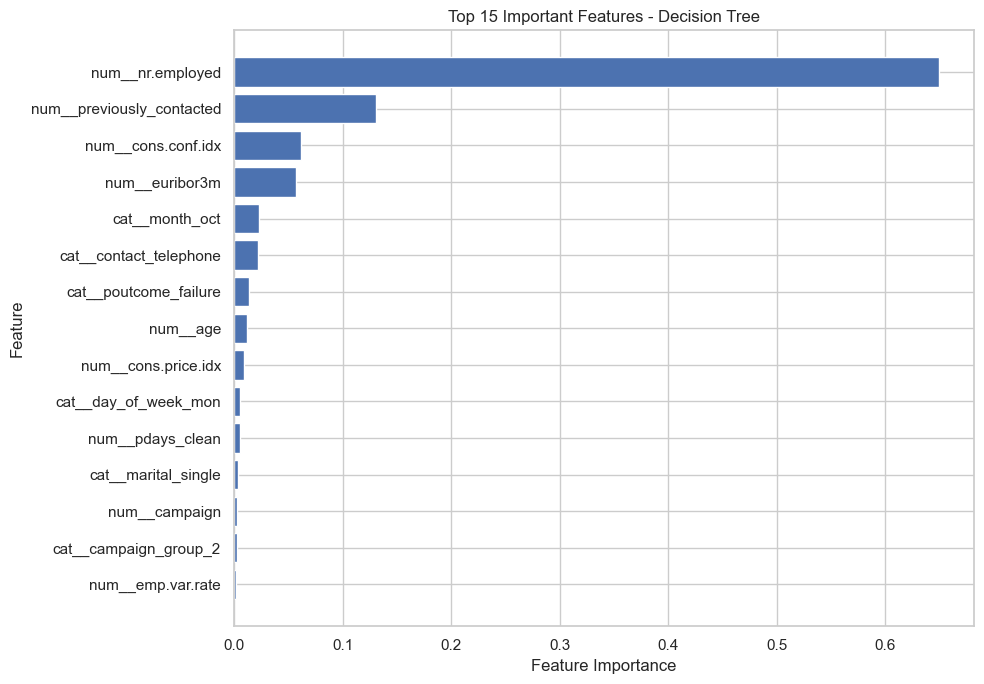

In [97]:
top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Important Features - Decision Tree")
plt.tight_layout()
plt.show()

In [98]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing: imputation + scaling
nn_numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: imputation + One-Hot Encoding
nn_categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
nn_preprocessor = ColumnTransformer(transformers=[
    ("num", nn_numerical_pipeline, numerical_features),
    ("cat", nn_categorical_pipeline, categorical_features)
])

In [100]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

# Create the Neural Network pipeline
neural_network_model = Pipeline(steps=[
    ("preprocessor", nn_preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=300,
        random_state=42,
        early_stopping=False
    ))
])

# Train the Neural Network
neural_network_model.fit(X_train, y_train)

print("Neural Network trained successfully!")

Neural Network trained successfully!


C:\Users\ACER\Anaconda\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


In [101]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predict the test set
y_pred_nn = neural_network_model.predict(X_test)

# Get probability of the positive class ("yes")
yes_index_nn = list(neural_network_model.classes_).index("yes")
y_prob_nn = neural_network_model.predict_proba(X_test)[:, yes_index_nn]

# Display evaluation results
print("Accuracy:",
      accuracy_score(y_test, y_pred_nn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nn))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    y_pred_nn,
    labels=["no", "yes"]
))

print("\nROC-AUC:",
      roc_auc_score(
          (y_test == "yes").astype(int),
          y_prob_nn
      ))

Accuracy: 0.8630403108305003

Classification Report:
              precision    recall  f1-score   support

          no       0.91      0.93      0.92      7308
         yes       0.37      0.32      0.34       928

    accuracy                           0.86      8236
   macro avg       0.64      0.62      0.63      8236
weighted avg       0.85      0.86      0.86      8236


Confusion Matrix:
[[6815  493]
 [ 635  293]]

ROC-AUC: 0.6642020642234301


In [102]:
trained_nn = neural_network_model.named_steps["classifier"]

print("Number of iterations:", trained_nn.n_iter_)
print("Final training loss:", trained_nn.loss_)
print("Network architecture:", trained_nn.hidden_layer_sizes)
print("Maximum iterations:", trained_nn.max_iter)

Number of iterations: 300
Final training loss: 0.12033586317666493
Network architecture: (64, 32)
Maximum iterations: 300


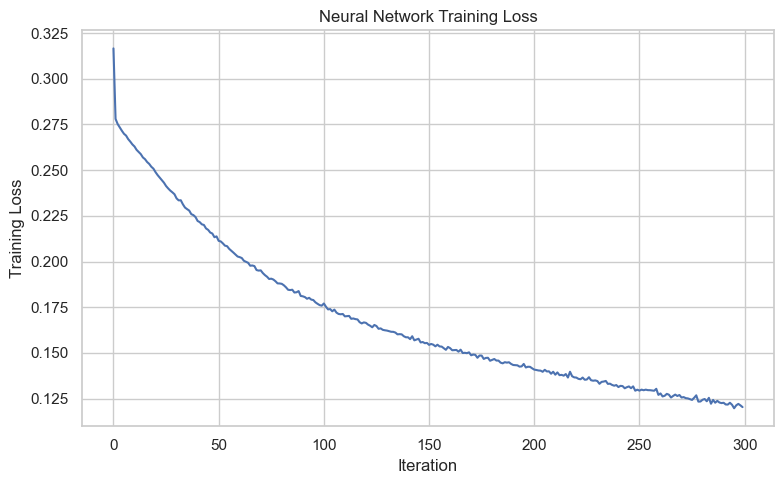

In [103]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(trained_nn.loss_curve_)

plt.xlabel("Iteration")
plt.ylabel("Training Loss")
plt.title("Neural Network Training Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

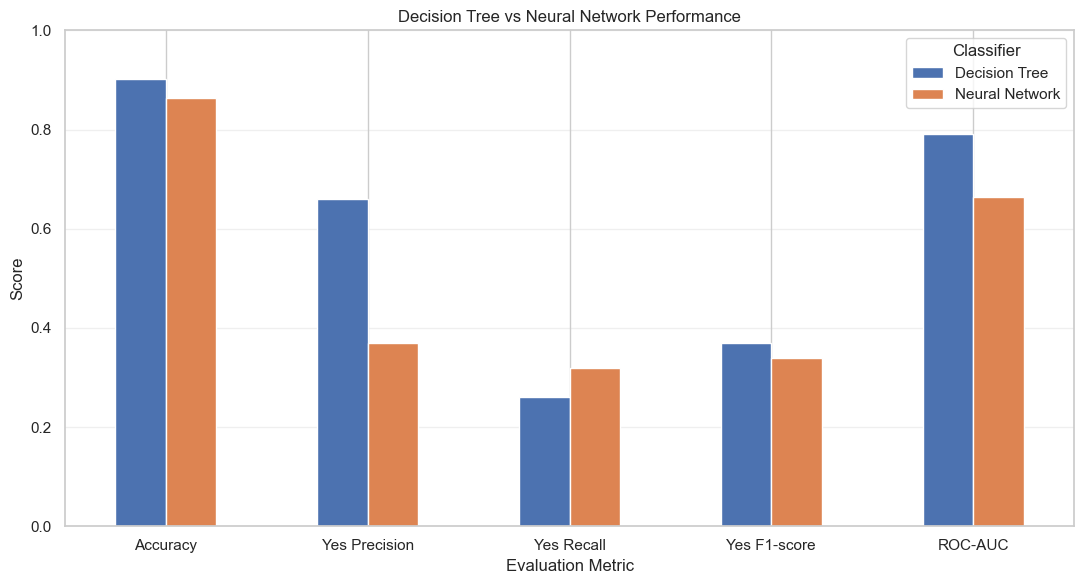

In [104]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Decision Tree": [0.9014, 0.66, 0.26, 0.37, 0.7909],
    "Neural Network": [0.8630, 0.37, 0.32, 0.34, 0.6642]
}, index=["Accuracy", "Yes Precision", "Yes Recall",
          "Yes F1-score", "ROC-AUC"])

comparison.plot(kind="bar", figsize=(11, 6))

plt.title("Decision Tree vs Neural Network Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Classifier")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

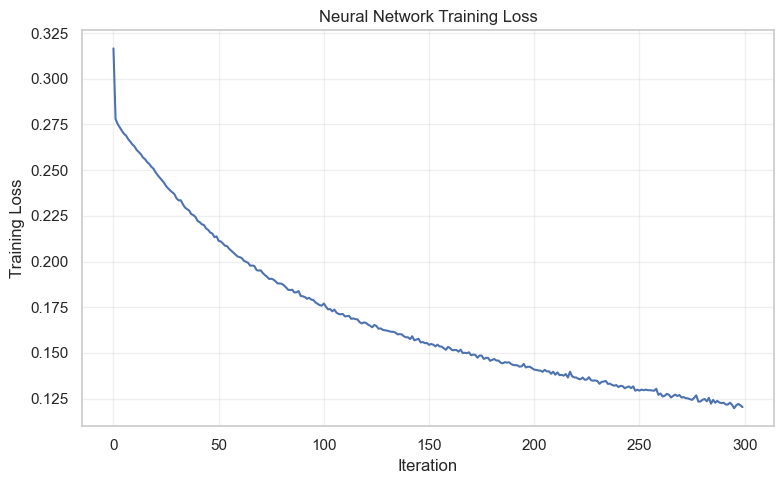

Iterations: 300
Final training loss: 0.12033586317666493


In [105]:
trained_nn = neural_network_model.named_steps["classifier"]

plt.figure(figsize=(8, 5))
plt.plot(trained_nn.loss_curve_)

plt.title("Neural Network Training Loss")
plt.xlabel("Iteration")
plt.ylabel("Training Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Iterations:", trained_nn.n_iter_)
print("Final training loss:", trained_nn.loss_)

In [106]:
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

neural_network_model = Pipeline(steps=[
    ("preprocessor", nn_preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=800,
        random_state=42,
        early_stopping=False
    ))
])

neural_network_model.fit(X_train, y_train)

print("Neural Network trained!")

Neural Network trained!


In [107]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y_pred_nn = neural_network_model.predict(X_test)

yes_index_nn = list(neural_network_model.classes_).index("yes")

y_prob_nn = neural_network_model.predict_proba(X_test)[:, yes_index_nn]

print("Accuracy:", accuracy_score(y_test, y_pred_nn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nn))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nn, labels=["no", "yes"]))

print("\nROC-AUC:", roc_auc_score(
    (y_test == "yes").astype(int),
    y_prob_nn
))

trained_nn = neural_network_model.named_steps["classifier"]

print("\nIterations:", trained_nn.n_iter_)
print("Final training loss:", trained_nn.loss_)

Accuracy: 0.8516270033997086

Classification Report:
              precision    recall  f1-score   support

          no       0.92      0.92      0.92      7308
         yes       0.34      0.34      0.34       928

    accuracy                           0.85      8236
   macro avg       0.63      0.63      0.63      8236
weighted avg       0.85      0.85      0.85      8236


Confusion Matrix:
[[6698  610]
 [ 612  316]]

ROC-AUC: 0.6653416543985807

Iterations: 434
Final training loss: 0.10573192426225832


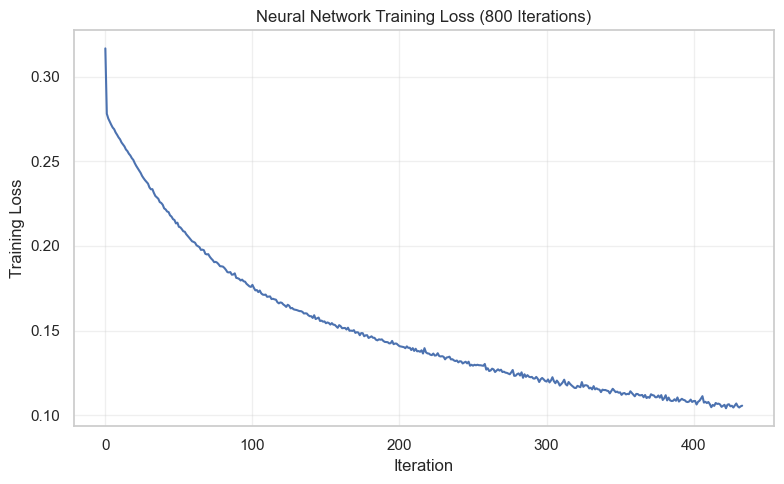

In [108]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(trained_nn.loss_curve_)

plt.title("Neural Network Training Loss (800 Iterations)")
plt.xlabel("Iteration")
plt.ylabel("Training Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [110]:
# Features excluded from clustering
excluded_clustering_features = ["y", "duration", "pdays"]

# Select all remaining features
clustering_features = [
    col for col in df_clean.columns
    if col not in excluded_clustering_features
]

# Create clustering dataset
X_clustering = df_clean[clustering_features].copy()

# Separate numerical and categorical features
clustering_categorical_features = (
    X_clustering.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
)

clustering_numerical_features = (
    X_clustering.select_dtypes(
        include=["number"]
    ).columns.tolist()
)

print("Clustering dataset shape:", X_clustering.shape)

print("\nExcluded features:")
print(excluded_clustering_features)

print("\nNumerical features:")
print(clustering_numerical_features)

print("\nCategorical features:")
print(clustering_categorical_features)

print("\nTarget included:", "y" in X_clustering.columns)
print("Duration included:", "duration" in X_clustering.columns)
print("Original pdays included:", "pdays" in X_clustering.columns)

Clustering dataset shape: (41176, 22)

Excluded features:
['y', 'duration', 'pdays']

Numerical features:
['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'pdays_clean']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'age_group', 'campaign_group']

Target included: False
Duration included: False
Original pdays included: False


In [111]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
clustering_numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
clustering_categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
clustering_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            clustering_numerical_pipeline,
            clustering_numerical_features
        ),
        (
            "cat",
            clustering_categorical_pipeline,
            clustering_categorical_features
        )
    ]
)

print("Clustering preprocessing pipeline created successfully!")

Clustering preprocessing pipeline created successfully!


In [112]:
# Features excluded from clustering
excluded_clustering_features = [
    "y",
    "duration",
    "pdays",
    "age_group",
    "campaign_group"
]

# Select clustering features
clustering_features = [
    col for col in df_clean.columns
    if col not in excluded_clustering_features
]

# Create clustering dataset
X_clustering = df_clean[clustering_features].copy()

# Separate numerical and categorical features
clustering_categorical_features = (
    X_clustering.select_dtypes(
        include=["object", "category"]
    ).columns.tolist()
)

clustering_numerical_features = (
    X_clustering.select_dtypes(
        include=["number"]
    ).columns.tolist()
)

print("Clustering dataset shape:", X_clustering.shape)

print("\nNumerical features:")
print(clustering_numerical_features)

print("\nCategorical features:")
print(clustering_categorical_features)

print("\nExcluded columns:")
print(excluded_clustering_features)

Clustering dataset shape: (41176, 20)

Numerical features:
['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'pdays_clean']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Excluded columns:
['y', 'duration', 'pdays', 'age_group', 'campaign_group']


In [114]:
import numpy as np
from scipy import sparse

if sparse.issparse(X_clustering_processed):
    contains_missing = np.isnan(
        X_clustering_processed.data
    ).any()
else:
    contains_missing = np.isnan(
        X_clustering_processed
    ).any()

print("Original shape:", X_clustering.shape)
print("Processed shape:", X_clustering_processed.shape)
print("Data type:", type(X_clustering_processed))
print("Contains missing values:", contains_missing)

Original shape: (41176, 20)
Processed shape: (41176, 63)
Data type: <class 'numpy.ndarray'>
Contains missing values: False


In [119]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import os

os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() or 4)

# Values of K to investigate
k_values = range(2, 11)

inertia_values = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_clustering_processed)

    inertia_values.append(kmeans.inertia_)

    print(f"K = {k}, Inertia = {kmeans.inertia_:.2f}")

K = 2, Inertia = 492758.70
K = 3, Inertia = 440005.97
K = 4, Inertia = 413333.80
K = 5, Inertia = 384193.67
K = 6, Inertia = 369513.45
K = 7, Inertia = 341407.75
K = 8, Inertia = 326052.82
K = 9, Inertia = 315709.24
K = 10, Inertia = 302184.74


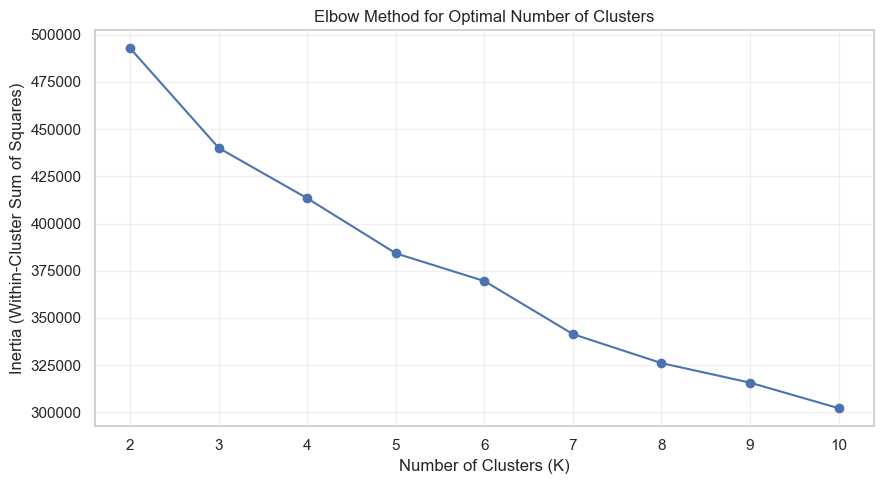

In [116]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.xticks(list(k_values))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [117]:
from sklearn.metrics import silhouette_score

silhouette_values = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_clustering_processed)

    score = silhouette_score(
        X_clustering_processed,
        labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_values.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.2837
K = 3, Silhouette Score = 0.2778
K = 4, Silhouette Score = 0.1401
K = 5, Silhouette Score = 0.1465
K = 6, Silhouette Score = 0.1371
K = 7, Silhouette Score = 0.1587
K = 8, Silhouette Score = 0.1471
K = 9, Silhouette Score = 0.1488
K = 10, Silhouette Score = 0.1589


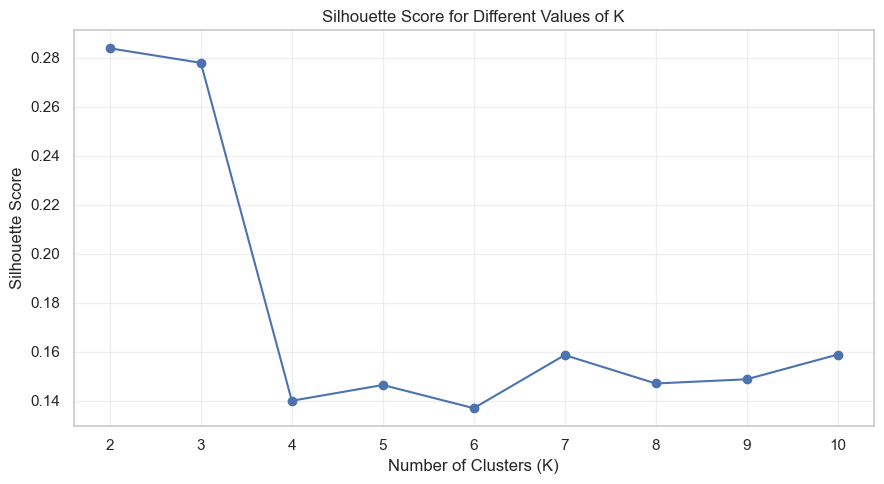

In [118]:
plt.figure(figsize=(9, 5))

plt.plot(
    list(range(2, 11)),
    silhouette_values,
    marker="o"
)

plt.title("Silhouette Score for Different Values of K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [120]:
from sklearn.cluster import KMeans

final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = final_kmeans.fit_predict(
    X_clustering_processed
)

print("K-Means training completed!")

K-Means training completed!


In [121]:
clustered_df = X_clustering.copy()

clustered_df["cluster"] = cluster_labels

print(clustered_df.head())

   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  campaign  previous     poutcome  emp.var.rate  \
0   may         mon         1         0  nonexistent           1.1   
1   may         mon         1         0  nonexistent           1.1   
2   may         mon         1         0  nonexistent           1.1   
3   may         mon         1         0  nonexistent           1.1   
4   may         mon         1         0  nonexistent           1.1   

   cons.price.idx  cons.conf.idx  euribor3m  nr.employed  \
0          93.994          -36.4      4.857       5191.0   
1 

In [122]:
cluster_counts = clustered_df["cluster"].value_counts().sort_index()

print("Number of customers in each cluster:")
print(cluster_counts)

print("\nPercentage of customers in each cluster:")

cluster_percentages = (
    clustered_df["cluster"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(cluster_percentages.round(2))

Number of customers in each cluster:
cluster
0    12002
1    27637
2     1537
Name: count, dtype: int64

Percentage of customers in each cluster:
cluster
0    29.15
1    67.12
2     3.73
Name: proportion, dtype: float64


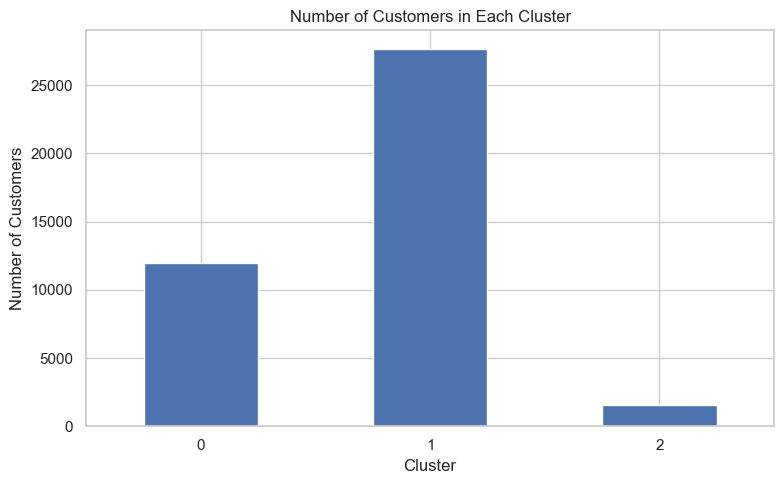

In [123]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

cluster_counts.plot(
    kind="bar",
    rot=0
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [124]:
# Select numerical features for cluster profiling
numeric_profile = clustered_df.groupby("cluster")[
    clustering_numerical_features
].mean()

print(numeric_profile.round(2))

           age  campaign  previous  emp.var.rate  cons.price.idx  \
cluster                                                            
0        39.39      2.13      0.32         -2.03           92.99   
1        40.19      2.80      0.03          1.12           93.84   
2        41.93      1.83      1.69         -2.09           93.35   

         cons.conf.idx  euribor3m  nr.employed  previously_contacted  \
cluster                                                                
0               -43.19       1.20      5077.95                  0.00   
1               -39.46       4.82      5213.42                  0.00   
2               -38.33       0.98      5028.64                  0.99   

         pdays_clean  
cluster               
0                NaN  
1                NaN  
2               6.01  


In [125]:
job_distribution = pd.crosstab(
    clustered_df["cluster"],
    clustered_df["job"],
    normalize="index"
) * 100

print(job_distribution.round(2))

job      admin.  blue-collar  entrepreneur  housemaid  management  retired  \
cluster                                                                      
0         26.05        22.17          3.07       1.63        6.71     6.21   
1         24.66        23.39          3.84       2.97        7.27     2.88   
2         31.03         8.39          1.69       2.73        7.22    11.58   

job      self-employed  services  student  technician  unemployed  unknown  
cluster                                                                     
0                 3.32      9.78     4.51       13.61        2.42     0.52  
1                 3.58      9.83     0.70       17.60        2.38     0.90  
2                 2.08      4.94     9.17       15.61        4.23     1.30  


In [126]:
# Add the target only AFTER clustering is complete
clustered_df["y"] = df_clean["y"].values

# Count yes/no subscriptions in each cluster
subscription_counts = pd.crosstab(
    clustered_df["cluster"],
    clustered_df["y"]
)

print("Subscription counts by cluster:")
print(subscription_counts)

# Calculate subscription rate in each cluster
subscription_rates = (
    clustered_df.groupby("cluster")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
)

print("\nSubscription rate by cluster (%):")
print(subscription_rates.round(2))

Subscription counts by cluster:
y           no   yes
cluster             
0         9668  2334
1        26302  1335
2          567   970

Subscription rate by cluster (%):
cluster
0    19.45
1     4.83
2    63.11
Name: y, dtype: float64


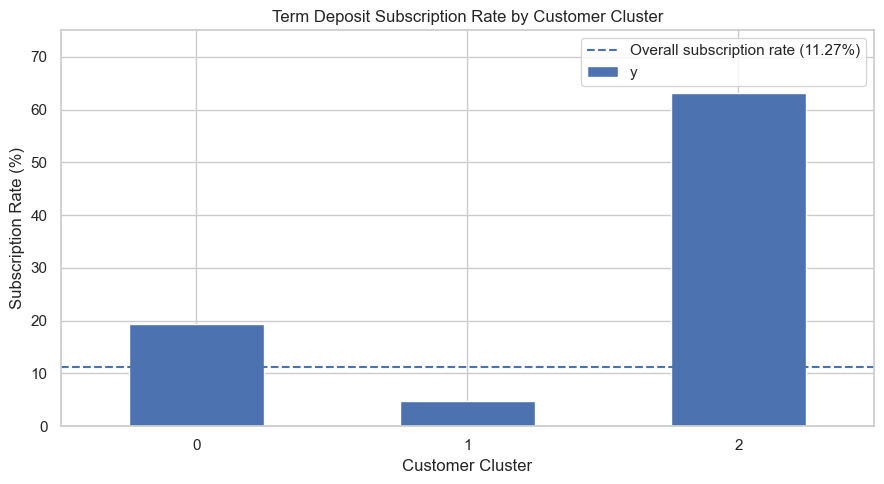

In [127]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

subscription_rates.plot(
    kind="bar",
    rot=0
)

plt.axhline(
    y=11.27,
    linestyle="--",
    label="Overall subscription rate (11.27%)"
)

plt.title("Term Deposit Subscription Rate by Customer Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Subscription Rate (%)")
plt.legend()
plt.ylim(0, 75)

plt.tight_layout()
plt.show()

In [128]:
 # Categorical features to investigate
categorical_profile_features = [
    "marital",
    "education",
    "contact",
    "poutcome",
    "housing",
    "loan"
]

for feature in categorical_profile_features:

    print(f"\n{'=' * 50}")
    print(f"Distribution of {feature} by cluster")
    print("=" * 50)

    distribution = pd.crosstab(
        clustered_df["cluster"],
        clustered_df[feature],
        normalize="index"
    ) * 100

    print(distribution.round(2))


Distribution of marital by cluster
marital  divorced  married  single  unknown
cluster                                    
0           10.32    54.60   34.84     0.23
1           11.67    63.55   24.61     0.17
2            9.50    52.44   37.74     0.33

Distribution of education by cluster
education  basic.4y  basic.6y  basic.9y  high.school  illiterate  \
cluster                                                            
0              9.21      5.33     14.88        24.79        0.04   
1             10.60      5.82     14.97        22.44        0.04   
2              9.24      2.80      7.94        21.73        0.07   

education  professional.course  university.degree  unknown  
cluster                                                     
0                        11.62              30.07     4.06  
1                        13.17              28.82     4.14  
2                        13.34              38.45     6.44  

Distribution of contact by cluster
contact  cellular  telep

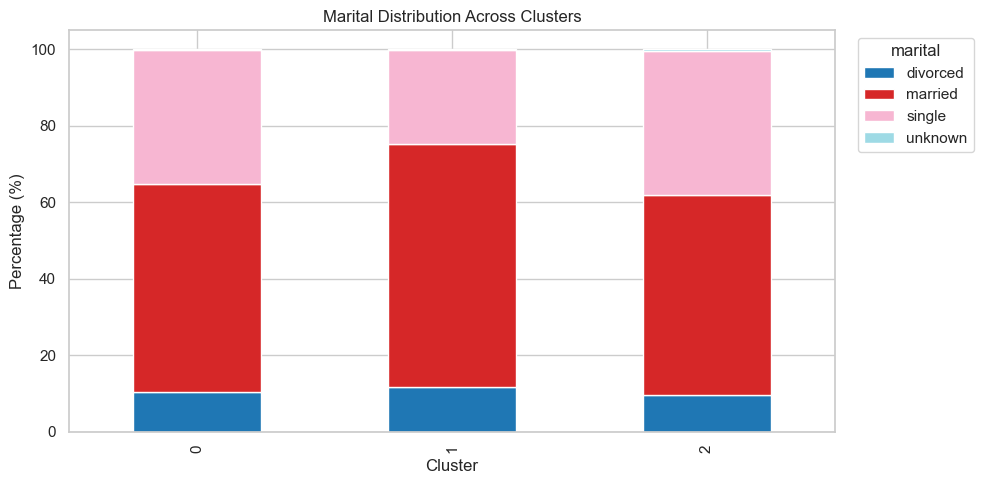

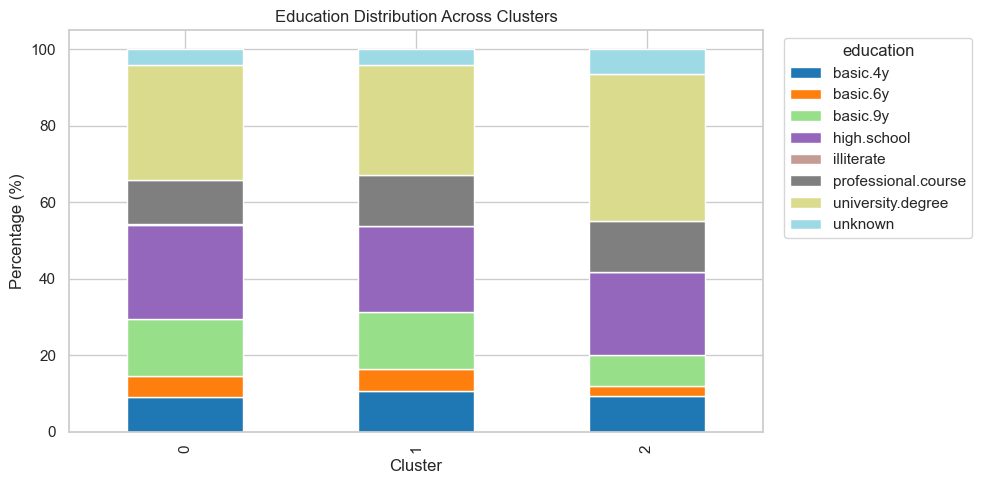

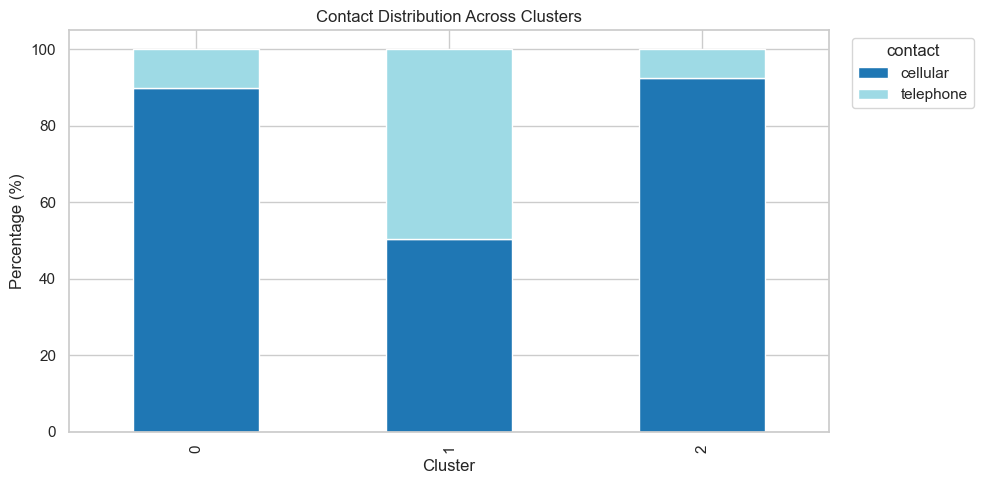

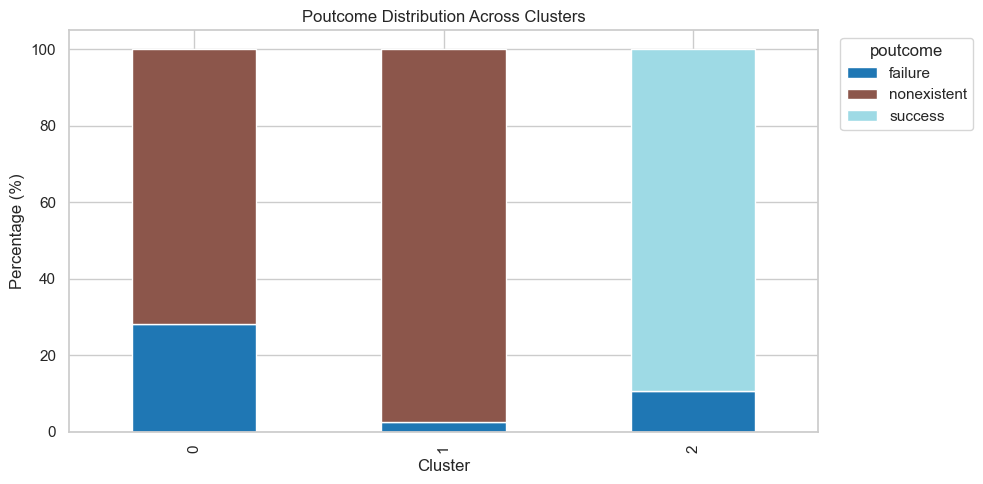

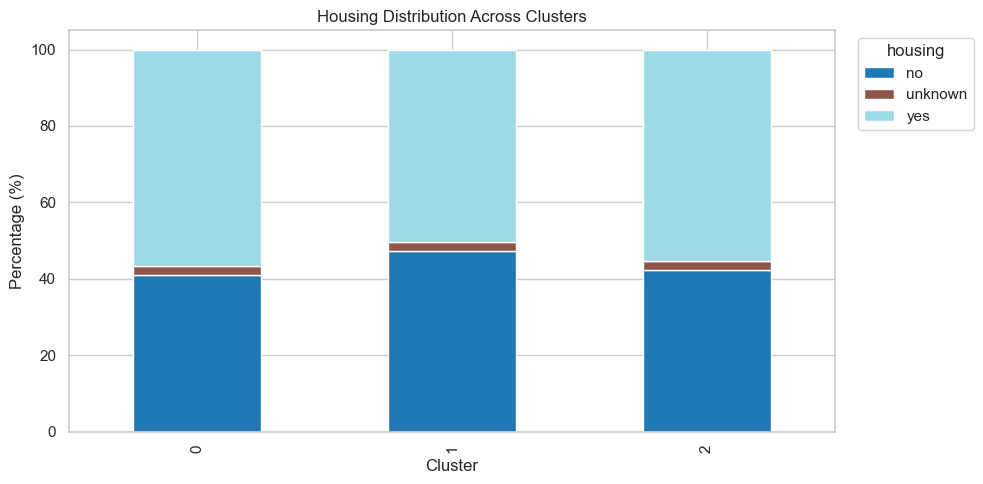

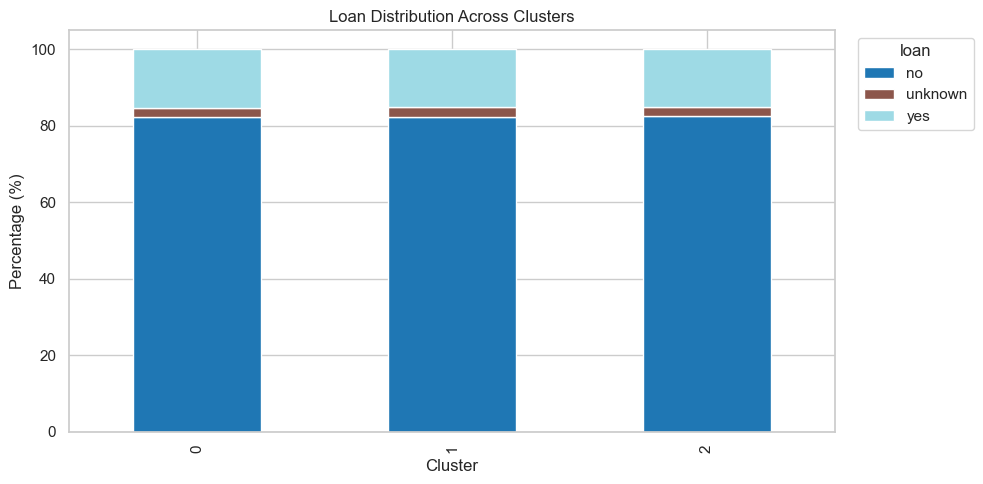

In [129]:
import matplotlib.pyplot as plt

for feature in categorical_profile_features:

    distribution = pd.crosstab(
        clustered_df["cluster"],
        clustered_df[feature],
        normalize="index"
    ) * 100

    ax = distribution.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5),
        colormap="tab20"
    )

    plt.title(f"{feature.title()} Distribution Across Clusters")
    plt.xlabel("Cluster")
    plt.ylabel("Percentage (%)")
    plt.legend(
        title=feature,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

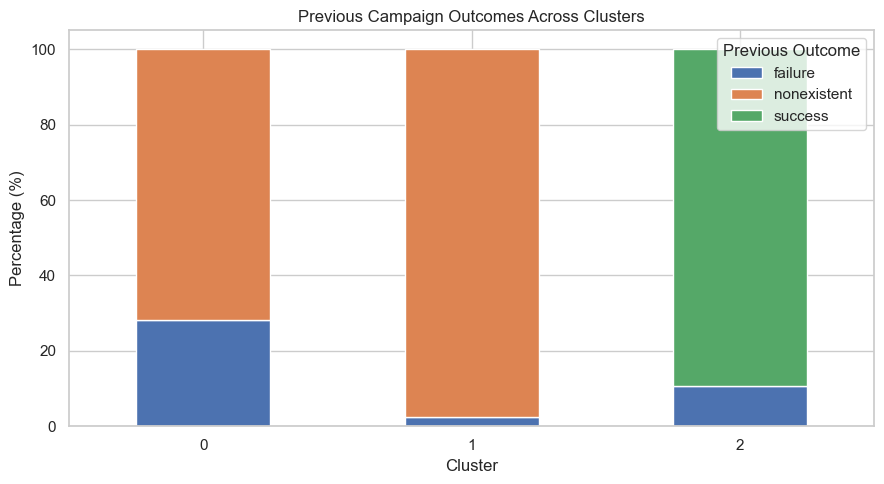

In [130]:
import matplotlib.pyplot as plt
import pandas as pd

poutcome_distribution = pd.crosstab(
    clustered_df["cluster"],
    clustered_df["poutcome"],
    normalize="index"
) * 100

poutcome_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Previous Campaign Outcomes Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Percentage (%)")
plt.legend(title="Previous Outcome")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [131]:
# Create a separate DataFrame for Apriori
apriori_df = df_clean.copy()

# Age groups
apriori_df["age_group"] = pd.cut(
    apriori_df["age"],
    bins=[16, 25, 35, 45, 55, 65, 100],
    labels=[
        "17-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65",
        "66+"
    ]
)

# Campaign contact groups
apriori_df["campaign_group"] = pd.cut(
    apriori_df["campaign"],
    bins=[0, 1, 2, 3, 5, 10, float("inf")],
    labels=[
        "1",
        "2",
        "3",
        "4-5",
        "6-10",
        "11+"
    ]
)

# Previous contact groups
apriori_df["previous_group"] = pd.cut(
    apriori_df["previous"],
    bins=[-1, 0, 1, float("inf")],
    labels=[
        "0",
        "1",
        "2+"
    ]
)

print(apriori_df[
    ["age", "age_group",
     "campaign", "campaign_group",
     "previous", "previous_group"]
].head(10))

   age age_group  campaign campaign_group  previous previous_group
0   56     56-65         1              1         0              0
1   57     56-65         1              1         0              0
2   37     36-45         1              1         0              0
3   40     36-45         1              1         0              0
4   56     56-65         1              1         0              0
5   45     36-45         1              1         0              0
6   59     56-65         1              1         0              0
7   41     36-45         1              1         0              0
8   24     17-25         1              1         0              0
9   25     17-25         1              1         0              0


In [132]:
apriori_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "day_of_week",
    "poutcome",
    "age_group",
    "campaign_group",
    "previous_group",
    "previously_contacted",
    "y"
]

apriori_data = apriori_df[apriori_features].copy()

print("Apriori dataset shape:", apriori_data.shape)

print("\nColumns included:")
print(apriori_data.columns.tolist())

print("\nMissing values:")
print(apriori_data.isnull().sum())

Apriori dataset shape: (41176, 15)

Columns included:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'age_group', 'campaign_group', 'previous_group', 'previously_contacted', 'y']

Missing values:
job                     0
marital                 0
education               0
default                 0
housing                 0
loan                    0
contact                 0
month                   0
day_of_week             0
poutcome                0
age_group               0
campaign_group          0
previous_group          0
previously_contacted    0
y                       0
dtype: int64


In [133]:
transactions = []

for _, row in apriori_data.iterrows():

    transaction = []

    for column in apriori_features:

        item = f"{column}={row[column]}"

        transaction.append(item)

    transactions.append(transaction)

# Display the first transaction
print("First customer transaction:")
print(transactions[0])    

First customer transaction:
['job=housemaid', 'marital=married', 'education=basic.4y', 'default=no', 'housing=no', 'loan=no', 'contact=telephone', 'month=may', 'day_of_week=mon', 'poutcome=nonexistent', 'age_group=56-65', 'campaign_group=1', 'previous_group=0', 'previously_contacted=0', 'y=no']


In [134]:
%pip install mlxtend


   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------------------------------

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.61.0 requires numpy<2.2,>=1.24, but you have numpy 2.5.5 which is incompatible.
sklearn-compat 0.1.3 requires scikit-learn<1.7,>=1.2, but you have scikit-learn 1.9.1 which is incompatible.
streamlit 1.45.1 requires pandas<3,>=1.4.0, but you have pandas 3.1.1 which is incompatible.


   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit-learn]
   ------------------------- -------------- 5/8 [scikit

In [135]:
from mlxtend.preprocessing import TransactionEncoder

# Initialize encoder
te = TransactionEncoder()

# Fit and transform transactions
transaction_array = te.fit(
    transactions
).transform(transactions)

# Create DataFrame
apriori_encoded = pd.DataFrame(
    transaction_array,
    columns=te.columns_
)

print("Encoded dataset shape:", apriori_encoded.shape)

print("\nFirst five rows:")
display(apriori_encoded.head())

Encoded dataset shape: (41176, 72)

First five rows:


,age_group=17-25,age_group=26-35,age_group=36-45,age_group=46-55,age_group=56-65,age_group=66+,campaign_group=1,campaign_group=11+,campaign_group=2,campaign_group=3,campaign_group=4-5,campaign_group=6-10,contact=cellular,contact=telephone,day_of_week=fri,day_of_week=mon,day_of_week=thu,day_of_week=tue,day_of_week=wed,default=no,default=unknown,default=yes,education=basic.4y,education=basic.6y,education=basic.9y,education=high.school,education=illiterate,education=professional.course,education=university.degree,education=unknown,housing=no,housing=unknown,housing=yes,job=admin.,job=blue-collar,job=entrepreneur,job=housemaid,job=management,job=retired,job=self-employed,job=services,job=student,job=technician,job=unemployed,job=unknown,loan=no,loan=unknown,loan=yes,marital=divorced,marital=married,marital=single,marital=unknown,month=apr,month=aug,month=dec,month=jul,month=jun,month=mar,month=may,month=nov,month=oct,month=sep,poutcome=failure,poutcome=nonexistent,poutcome=success,previous_group=0,previous_group=1,previous_group=2+,previously_contacted=0,previously_contacted=1,y=no,y=yes
0,False,False,False,False,True,False,True,False,False,False,False,False,False,True,False,True,False,False,False,True,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,True,False,False,True,False,True,False
1,False,False,False,False,True,False,True,False,False,False,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,True,False,False,True,False,True,False
2,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,True,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,True,False,False,True,False,True,False
3,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,True,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,True,False,False,True,False,True,False
4,False,False,False,False,True,False,True,False,False,False,False,False,False,True,False,True,False,False,False,True,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,True,False,False,True,False,True,False


In [136]:
from mlxtend.frequent_patterns import apriori

frequent_itemsets = apriori(
    apriori_encoded,
    min_support=0.05,
    use_colnames=True,
    max_len=3
)

# Add itemset length to make the results easier to inspect
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)

# Display the 20 most frequent itemsets
frequent_itemsets_sorted = frequent_itemsets.sort_values(
    by="support",
    ascending=False
)

display(frequent_itemsets_sorted.head(20))

print("Total frequent itemsets:", len(frequent_itemsets))
print("\nItemsets by length:")
print(frequent_itemsets["length"].value_counts().sort_index())

,support,itemsets,length
46,0.963207,(previously_contacted=0),1
47,0.887337,(y=no),1
567,0.874029,"(y=no, previously_contacted=0)",2
43,0.863391,(poutcome=nonexistent),1
558,0.863391,"(poutcome=nonexistent, previous_group=0)",2
559,0.863391,"(poutcome=nonexistent, previously_contacted=0)",2
2676,0.863391,"(poutcome=nonexistent, previous_group=0, previ...",3
562,0.863391,"(previous_group=0, previously_contacted=0)",2
44,0.863391,(previous_group=0),1
31,0.824218,(loan=no),1


Total frequent itemsets: 2684

Itemsets by length:
length
1      49
2     520
3    2115
Name: count, dtype: int64


In [139]:
# Re-run Apriori with a lower support threshold
frequent_itemsets_2 = apriori(
    apriori_encoded,
    min_support=0.02,
    use_colnames=True,
    max_len=3
)

print("Total frequent itemsets:", len(frequent_itemsets_2))

# Generate association rules
rules_2 = association_rules(
    frequent_itemsets_2,
    metric="confidence",
    min_threshold=0.20
)

print("Total association rules:", len(rules_2))

# Keep rules predicting subscription
subscription_rules = rules_2[
    rules_2["consequents"].apply(
        lambda items: "y=yes" in items
    )
].copy()

# Ensure the antecedent does not already contain the target
subscription_rules = subscription_rules[
    subscription_rules["antecedents"].apply(
        lambda items: not any(
            str(item).startswith("y=") for item in items
        )
    )
]

# Keep positive associations
subscription_rules = subscription_rules[
    subscription_rules["lift"] > 1
]

# Sort by lift
subscription_rules = subscription_rules.sort_values(
    by=["lift", "confidence"],
    ascending=False
)

display(
    subscription_rules[
        [
            "antecedents",
            "consequents",
            "support",
            "confidence",
            "lift"
        ]
    ].head(20)
)

print(
    "Total rules predicting y=yes:",
    len(subscription_rules)
)

Total frequent itemsets: 6070
Total association rules: 18116


,antecedents,consequents,support,confidence,lift
18102,(poutcome=success),"(previously_contacted=1, y=yes)",0.021712,0.651129,27.725837
18103,(previously_contacted=1),"(poutcome=success, y=yes)",0.021712,0.590099,27.178878
9495,(poutcome=success),"(contact=cellular, y=yes)",0.020109,0.603059,6.446406
9532,(previously_contacted=1),"(contact=cellular, y=yes)",0.021760,0.591419,6.321982
13579,(poutcome=success),"(default=no, y=yes)",0.021032,0.630736,6.189507
13617,(previously_contacted=1),"(default=no, y=yes)",0.022756,0.618482,6.069258
13576,"(poutcome=success, default=no)",(y=yes),0.021032,0.659056,5.849817
9492,"(poutcome=success, contact=cellular)",(y=yes),0.020109,0.651969,5.786906
1126,(poutcome=success),(y=yes),0.021712,0.651129,5.779453
18099,"(poutcome=success, previously_contacted=1)",(y=yes),0.021712,0.651129,5.779453


Total rules predicting y=yes: 17


In [140]:
# Keep only rules where the consequent is exactly y=yes
direct_subscription_rules = rules_2[
    rules_2["consequents"].apply(
        lambda items: items == frozenset(["y=yes"])
    )
].copy()

# Keep positive associations
direct_subscription_rules = direct_subscription_rules[
    direct_subscription_rules["lift"] > 1
]

# Sort by lift
direct_subscription_rules = direct_subscription_rules.sort_values(
    by="lift",
    ascending=False
)

display(
    direct_subscription_rules[
        [
            "antecedents",
            "consequents",
            "support",
            "confidence",
            "lift"
        ]
    ]
)

print(
    "Number of direct rules predicting y=yes:",
    len(direct_subscription_rules)
)

,antecedents,consequents,support,confidence,lift
13576,"(poutcome=success, default=no)",(y=yes),0.021032,0.659056,5.849817
9492,"(poutcome=success, contact=cellular)",(y=yes),0.020109,0.651969,5.786906
18099,"(poutcome=success, previously_contacted=1)",(y=yes),0.021712,0.651129,5.779453
1126,(poutcome=success),(y=yes),0.021712,0.651129,5.779453
13614,"(default=no, previously_contacted=1)",(y=yes),0.022756,0.645762,5.731812
9529,"(previously_contacted=1, contact=cellular)",(y=yes),0.021760,0.639087,5.672569
1140,(previously_contacted=1),(y=yes),0.023485,0.638284,5.665440
13601,"(previous_group=1, default=no)",(y=yes),0.022392,0.228387,2.027178
9517,"(previous_group=1, contact=cellular)",(y=yes),0.021979,0.213443,1.894534
1135,(previous_group=1),(y=yes),0.023485,0.212015,1.881855


Number of direct rules predicting y=yes: 10
